In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
import tensorflow as tf

from tensorflow.keras import backend as K

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression


from pylab import rcParams

from collections import Counter

In [ ]:
SEED = 42
K.clear_session()
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

**Cargar Datos**

In [ ]:
#Cargar Datos
df = pd.read_csv("../data/data.csv", encoding="latin1", sep=";")
df

,Group,Sex,Age,Patients number per hour,Arrival mode,Injury,Chief_complain,Mental,Pain,NRS_pain,...,BT,Saturation,KTAS_RN,Diagnosis in ED,Disposition,KTAS_expert,Error_group,Length of stay_min,KTAS duration_min,mistriage
0,2,2,71,3,3,2,right ocular pain,1,1,2,...,36.6,100,2,Corneal abrasion,1,4,2,86,"5,00",1
1,1,1,56,12,3,2,right forearm burn,1,1,2,...,36.5,NaN,4,"Burn of hand, firts degree dorsum",1,5,4,64,"3,95",1
2,2,1,68,8,2,2,"arm pain, Lt",1,1,2,...,36.6,98,4,"Fracture of surgical neck of humerus, closed",2,5,4,862,"1,00",1
3,1,2,71,8,1,1,ascites tapping,1,1,3,...,36.5,NaN,4,Alcoholic liver cirrhosis with ascites,1,5,6,108,"9,83",1
4,1,2,58,4,3,1,"distension, abd",1,1,3,...,36.5,NaN,4,Ascites,1,5,8,109,"6,60",1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1262,2,2,79,5,2,1,mental change,1,0,#BOÞ!,...,36.4,95,2,Cerebral infarction due to unspecified occlusi...,2,2,0,1995,"3,00",0
1263,2,2,81,2,3,1,dysuria,1,0,#BOÞ!,...,36.4,97,4,Dysuria,1,4,0,1000,"2,00",0
1264,2,2,81,17,2,1,dizziness,1,0,#BOÞ!,...,36.2,99,3,Dizziness and giddiness,1,3,0,310,"4,00",0
1265,2,1,81,2,2,2,"Sensory, Decreased",1,0,#BOÞ!,...,36.6,98,3,"Cord compression, unspecified",7,3,0,475,"5,00",0


**Valores nulos y tipo de datos**

In [ ]:
print(df.columns)
print(df.info())
df.head()

Index(['Group', 'Sex', 'Age', 'Patients number per hour', 'Arrival mode',
       'Injury', 'Chief_complain', 'Mental', 'Pain', 'NRS_pain', 'SBP', 'DBP',
       'HR', 'RR', 'BT', 'Saturation', 'KTAS_RN', 'Diagnosis in ED',
       'Disposition', 'KTAS_expert', 'Error_group', 'Length of stay_min',
       'KTAS duration_min', 'mistriage'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1267 entries, 0 to 1266
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Group                     1267 non-null   int64 
 1   Sex                       1267 non-null   int64 
 2   Age                       1267 non-null   int64 
 3   Patients number per hour  1267 non-null   int64 
 4   Arrival mode              1267 non-null   int64 
 5   Injury                    1267 non-null   int64 
 6   Chief_complain            1267 non-null   object
 7   Mental                    1267 non-null   

,Group,Sex,Age,Patients number per hour,Arrival mode,Injury,Chief_complain,Mental,Pain,NRS_pain,...,BT,Saturation,KTAS_RN,Diagnosis in ED,Disposition,KTAS_expert,Error_group,Length of stay_min,KTAS duration_min,mistriage
0,2,2,71,3,3,2,right ocular pain,1,1,2,...,36.6,100,2,Corneal abrasion,1,4,2,86,"5,00",1
1,1,1,56,12,3,2,right forearm burn,1,1,2,...,36.5,NaN,4,"Burn of hand, firts degree dorsum",1,5,4,64,"3,95",1
2,2,1,68,8,2,2,"arm pain, Lt",1,1,2,...,36.6,98,4,"Fracture of surgical neck of humerus, closed",2,5,4,862,"1,00",1
3,1,2,71,8,1,1,ascites tapping,1,1,3,...,36.5,NaN,4,Alcoholic liver cirrhosis with ascites,1,5,6,108,"9,83",1
4,1,2,58,4,3,1,"distension, abd",1,1,3,...,36.5,NaN,4,Ascites,1,5,8,109,"6,60",1


**Distribución Variable objetivo**

In [ ]:
print(df.shape)
print(pd.value_counts(df['KTAS_expert'], sort = True))

(1267, 24)
KTAS_expert
3    487
4    459
2    220
5     75
1     26
Name: count, dtype: int64


/tmp/ipykernel_2370/923478831.py:2: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  print(pd.value_counts(df['KTAS_expert'], sort = True))


Distribución de clases en el entrenamiento:
KTAS 1: 26 casos
KTAS 2: 220 casos
KTAS 3: 487 casos
KTAS 4: 459 casos
KTAS 5: 75 casos


/tmp/ipykernel_2370/1444202068.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f"KTAS {i}" for i in unique], y=counts, palette='viridis')


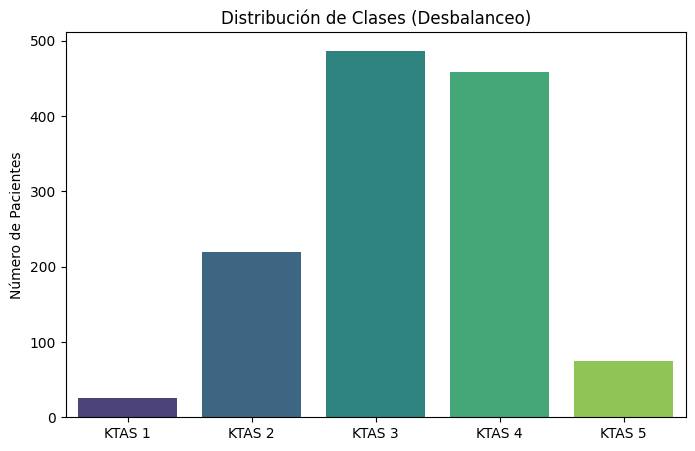

In [ ]:
unique, counts = np.unique(df['KTAS_expert'], return_counts=True)
clases_dict = dict(zip(unique, counts))

print("Distribución de clases en el entrenamiento:")
for clase, cantidad in clases_dict.items():
    print(f"KTAS {clase}: {cantidad} casos")

# Grafica
plt.figure(figsize=(8, 5))
sns.barplot(x=[f"KTAS {i}" for i in unique], y=counts, palette='viridis')
plt.title('Distribución de Clases (Desbalanceo)')
plt.ylabel('Número de Pacientes')
plt.show()

**Prepocesamiento Correo Alberto**

**Eliminacion de variables predictoras**

In [ ]:
cols_eliminar = [
    "Group",
    "NRS_pain",
    "Diagnosis in ED",
    "Disposition",
    "KTAS_RN",
    "Error_group",
    "Length of stay_min",
    "KTAS duration_min",
    "mistriage"
]

df_modelo = df.drop(columns=cols_eliminar, errors="ignore")

print("Columnas restantes:")
print(df_modelo.columns)

Columnas restantes:
Index(['Sex', 'Age', 'Patients number per hour', 'Arrival mode', 'Injury',
       'Chief_complain', 'Mental', 'Pain', 'SBP', 'DBP', 'HR', 'RR', 'BT',
       'Saturation', 'KTAS_expert'],
      dtype='object')


**Limpieza de Variables numericas**




In [ ]:

cols_clinicas = ["SBP", "DBP", "HR", "RR", "BT", "Saturation"]

for col in cols_clinicas:
    df_modelo[col] = df_modelo[col].astype(str).str.replace(',', '.').str.strip()
    df_modelo[col] = pd.to_numeric(df_modelo[col], errors='coerce')

print(df_modelo.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1267 entries, 0 to 1266
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Sex                       1267 non-null   int64  
 1   Age                       1267 non-null   int64  
 2   Patients number per hour  1267 non-null   int64  
 3   Arrival mode              1267 non-null   int64  
 4   Injury                    1267 non-null   int64  
 5   Chief_complain            1267 non-null   object 
 6   Mental                    1267 non-null   int64  
 7   Pain                      1267 non-null   int64  
 8   SBP                       1242 non-null   float64
 9   DBP                       1238 non-null   float64
 10  HR                        1247 non-null   float64
 11  RR                        1245 non-null   float64
 12  BT                        1249 non-null   float64
 13  Saturation                570 non-null    float64
 14  KTAS_exp

**Variables Categóricas**

In [ ]:
# Comprobar primero qué valores tiene cada variable
for col in ["Sex", "Injury", "Pain"]:
    print(col, sorted(df[col].dropna().unique()))

Sex [np.int64(1), np.int64(2)]
Injury [np.int64(1), np.int64(2)]
Pain [np.int64(0), np.int64(1)]


In [ ]:
# Injury: 1 = No, 2 = Yes  --> No=0, Yes=1
#Sex 1 = Female, 2 = Male --> 1=Mujer, 0=Hombre

df_modelo["Sex"] = df_modelo["Sex"].replace({1: 1, 2: 0})
df_modelo["Injury"] = df_modelo["Injury"].replace({1: 0, 2: 1})

In [ ]:
df_modelo["Arrival mode"].value_counts(dropna=False).sort_index()

,count
Arrival mode,
1,79
2,266
3,753
4,155
5,2
6,10
7,2


In [ ]:
df_modelo["Arrival_group"] = df_modelo["Arrival mode"].replace({
    1: "Walking",
    2: "Ambulance",
    3: "Private_Vehicle",
    4: "Ambulance",
    5: "Other",
    6: "Other",
    7: "Other"
})

arrival_dummies = pd.get_dummies(
    df_modelo["Arrival_group"],
    prefix="Arrival",
    dtype=int
)

In [ ]:


def map_clinical_categories(text):
    text = str(text).lower()
    categorias = []

    # Categorías basadas en "Red Flags" de urgencias (Quirónsalud)
    if any(x in text for x in ['chest', 'palpitation', 'heart', 'cardiac']):
        categorias.append('Cardiovascular_Agudo')

    if any(x in text for x in ['dyspnea', 'breath', 'respiratory', 'chok']):
        categorias.append('Dificultad_Respiratoria')

    if any(x in text for x in ['weakness', 'hemiparesis', 'palsy', 'speech', 'dysarthria', 'numbness']):
        categorias.append('Neurologico_Ictus')

    if any(x in text for x in ['mental', 'confus', 'unconscious', 'syncope', 'seizure', 'drowsy']):
        categorias.append('Alteracion_Conciencia')

    if any(x in text for x in ['abd', 'epigastric', 'stomach', 'melena', 'hematemesis', 'vomit']):
        categorias.append('Abdominal_Grave')

    if any(x in text for x in ['headache', 'ha', 'dizziness', 'vertigo']):
        categorias.append('Cefalea_Mareo')

    if any(x in text for x in ['injury', 'trauma', 'wound', 'laceration', 'burn', 'fracture']):
        categorias.append('Trauma_Accidente')

    if any(x in text for x in ['fever', 'chill', 'f/c', 'infection']):
        categorias.append('Infeccioso_Fiebre')

    if len(categorias) == 0:
        categorias.append('Otros_Sintomas')

    return categorias

df_modelo['Chief_complain_Cat'] = df_modelo['Chief_complain'].apply(map_clinical_categories)


from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()

df_motivos = pd.DataFrame(
    mlb.fit_transform(df_modelo['Chief_complain_Cat']),
    columns=mlb.classes_,
    index=df.index
)

df_modelo = df_modelo.drop(
    columns=["Chief_complain", "Chief_complain_Cat"],
    errors="ignore"
)

In [ ]:
print(df_modelo.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1267 entries, 0 to 1266
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Sex                       1267 non-null   int64  
 1   Age                       1267 non-null   int64  
 2   Patients number per hour  1267 non-null   int64  
 3   Arrival mode              1267 non-null   int64  
 4   Injury                    1267 non-null   int64  
 5   Mental                    1267 non-null   int64  
 6   Pain                      1267 non-null   int64  
 7   SBP                       1242 non-null   float64
 8   DBP                       1238 non-null   float64
 9   HR                        1247 non-null   float64
 10  RR                        1245 non-null   float64
 11  BT                        1249 non-null   float64
 12  Saturation                570 non-null    float64
 13  KTAS_expert               1267 non-null   int64  
 14  Arrival_

In [ ]:
print("Registros totales originales:", df.shape[0])
print("\nValores nulos por variable:")
print(df_modelo.isnull().sum())
print("\nRegistros con al menos un nulo:", df_modelo.isnull().any(axis=1).sum())

Registros totales originales: 1267

Valores nulos por variable:
Sex                           0
Age                           0
Patients number per hour      0
Arrival mode                  0
Injury                        0
Mental                        0
Pain                          0
SBP                          25
DBP                          29
HR                           20
RR                           22
BT                           18
Saturation                  697
KTAS_expert                   0
Arrival_group                 0
dtype: int64

Registros con al menos un nulo: 706


**Revisión final de las variables**

In [ ]:
columnas_revisar = [
    "Sex", "Age", "Patients number per hour", "Arrival mode",
    "Injury", "Pain", "NRS_pain", "SBP", "DBP",
    "HR", "RR", "BT", "Saturation", "Mental", "KTAS_expert"
]

for col in columnas_revisar:
    print("\n----------------------")
    print(col)
    print("----------------------")
    print("Nulos:", df[col].isna().sum())
    print("Valores únicos:", df[col].nunique())
    print(df[col].value_counts(dropna=False).sort_index().head(20))


----------------------
Sex
----------------------
Nulos: 0
Valores únicos: 2
Sex
1    606
2    661
Name: count, dtype: int64

----------------------
Age
----------------------
Nulos: 0
Valores únicos: 81
Age
16     9
17     4
18    10
19    11
20    12
21     9
22    25
23    11
24    21
25    16
26    15
27    25
28    11
29    21
30    14
31    11
32    14
33    16
34    20
35    16
Name: count, dtype: int64

----------------------
Patients number per hour
----------------------
Nulos: 0
Valores únicos: 16
Patients number per hour
1      16
2      31
3      82
4      85
5     160
6     143
7     136
8     147
9     137
10    113
11     56
12     84
13     34
14     13
15     22
17      8
Name: count, dtype: int64

----------------------
Arrival mode
----------------------
Nulos: 0
Valores únicos: 7
Arrival mode
1     79
2    266
3    753
4    155
5      2
6     10
7      2
Name: count, dtype: int64

----------------------
Injury
----------------------
Nulos: 0
Valores únicos: 2
Inju

In [ ]:
df["Saturation"] = df["Saturation"].astype(str).str.replace(",", ".").str.strip()
df["Saturation"] = pd.to_numeric(df["Saturation"], errors="coerce")

df[df["Saturation"] < 80][[
    "Saturation", "KTAS_expert", "Chief_complain", "Mental", "RR"
]]

,Saturation,KTAS_expert,Chief_complain,Mental,RR
61,78.0,1,dyspnea,2,22
132,68.0,1,dyspnea,1,26
434,76.0,2,dyspnea,1,20
1148,20.0,3,dizziness,1,20
1167,74.0,2,blood tinged sputum,1,24


In [ ]:


df_modelo.loc[(df_modelo["Saturation"] < 50) | (df_modelo["Saturation"] > 100), "Saturation"] = np.nan

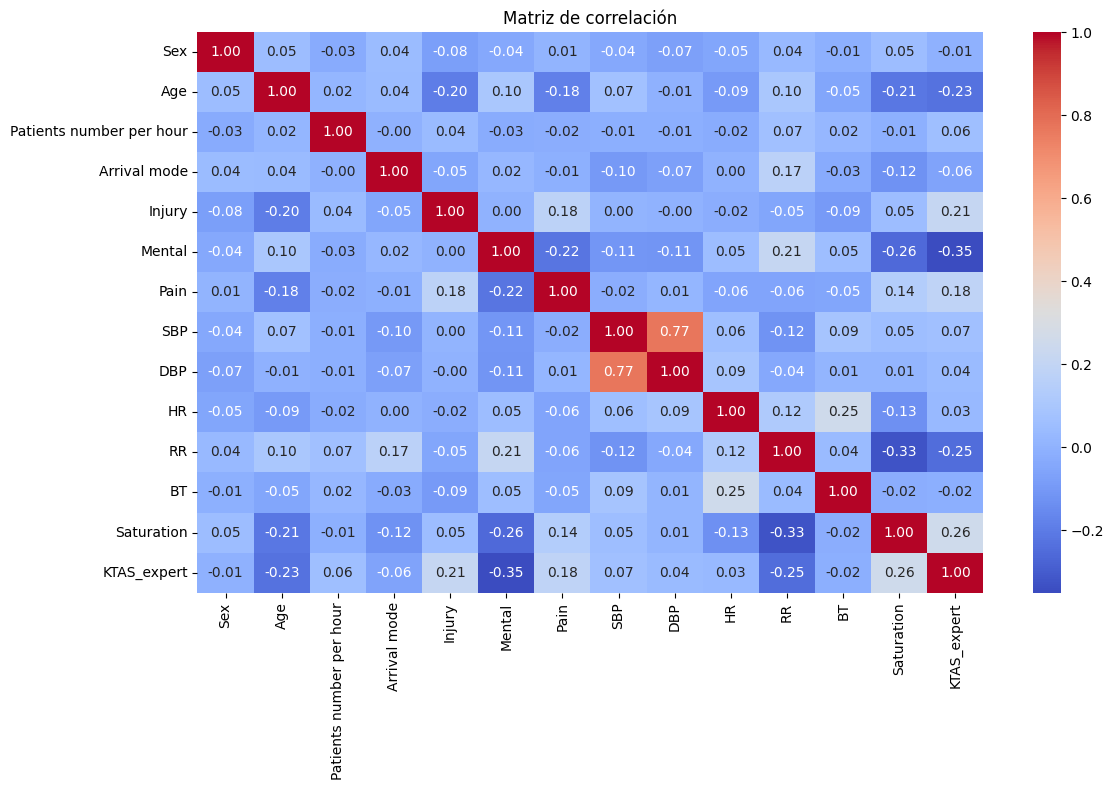


Correlación con KTAS_expert:
KTAS_expert                 1.000000
Saturation                  0.255240
Injury                      0.210452
Pain                        0.183484
SBP                         0.065164
Patients number per hour    0.058680
DBP                         0.036926
HR                          0.034838
Sex                        -0.005684
BT                         -0.015237
Arrival mode               -0.061392
Age                        -0.229602
RR                         -0.248003
Mental                     -0.349787
Name: KTAS_expert, dtype: float64


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df_modelo.corr(numeric_only=True)
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

# También correlación con la variable objetivo
print("\nCorrelación con KTAS_expert:")
print(corr["KTAS_expert"].sort_values(ascending=False))

# **DATASET A: Variables**

In [ ]:
from sklearn.model_selection import train_test_split
import pandas as pd

X = df_modelo[[
    "Sex", "Age", "Patients number per hour",
    "Injury", "Pain", "SBP", "DBP",
    "HR", "RR", "BT", "Saturation", "Mental"
]]

# Añadir variables Arrival mode y Chief_complain
X_completo = pd.concat([
    X.reset_index(drop=True),
    arrival_dummies.reset_index(drop=True),
    df_motivos.reset_index(drop=True)
], axis=1)

y = df_modelo["KTAS_expert"]

# División inicial: 80% entrenamiento / 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X_completo,
    y,
    train_size=0.8,
    random_state=42,
    stratify=y
)

# División interna del entrenamiento: 90% train_sub / 10% validación
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    train_size=0.9,
    random_state=42,
    stratify=y_train
)

# Función para ver representación de clases
def resumen_clases(y, nombre):
    resumen = pd.DataFrame({
        "n": y.value_counts().sort_index(),
        "%": (y.value_counts(normalize=True).sort_index() * 100).round(2)
    })
    print(f"\n{nombre}")
    print(resumen)

# Ver distribución de clases
resumen_clases(y, "Dataset completo")
resumen_clases(y_train, "Train inicial 80%")
resumen_clases(y_test, "Test 20%")
resumen_clases(y_train_sub, "Train_sub 90% del train")
resumen_clases(y_val, "Validación 10% del train")

# Ver tamaños finales
print("\nTamaños:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("X_train_sub:", X_train_sub.shape)
print("X_val:", X_val.shape)


Dataset completo
               n      %
KTAS_expert            
1             26   2.05
2            220  17.36
3            487  38.44
4            459  36.23
5             75   5.92

Train inicial 80%
               n      %
KTAS_expert            
1             21   2.07
2            176  17.37
3            389  38.40
4            367  36.23
5             60   5.92

Test 20%
              n      %
KTAS_expert           
1             5   1.97
2            44  17.32
3            98  38.58
4            92  36.22
5            15   5.91

Train_sub 90% del train
               n      %
KTAS_expert            
1             19   2.09
2            158  17.34
3            350  38.42
4            330  36.22
5             54   5.93

Validación 10% del train
              n      %
KTAS_expert           
1             2   1.96
2            18  17.65
3            39  38.24
4            37  36.27
5             6   5.88

Tamaños:
X_train: (1013, 25)
X_test: (254, 25)
X_train_sub: (911, 25)
X_val

Distribución de clases en el entrenamiento:
KTAS 1: 21 casos
KTAS 2: 176 casos
KTAS 3: 389 casos
KTAS 4: 367 casos
KTAS 5: 60 casos


/tmp/ipykernel_2031/3460078077.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f"KTAS {i}" for i in unique], y=counts, palette='viridis')


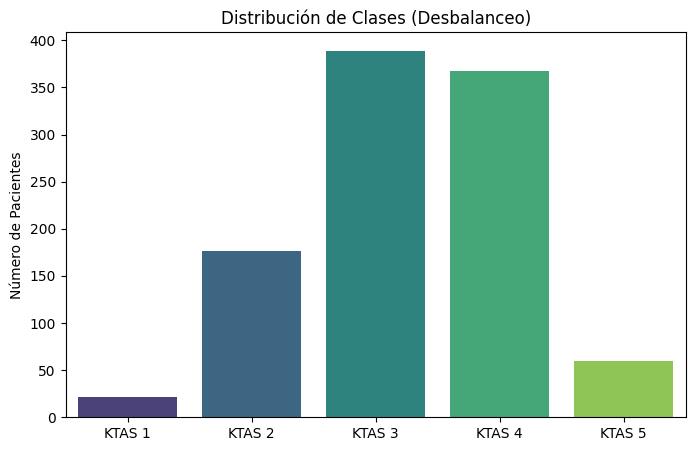

In [ ]:

# Contamos las frecuencias de cada clase en y_train_A
unique, counts = np.unique(y_train, return_counts=True)
clases_dict = dict(zip(unique, counts))

print("Distribución de clases en el entrenamiento:")
for clase, cantidad in clases_dict.items():
    print(f"KTAS {clase}: {cantidad} casos")

# Grafica
plt.figure(figsize=(8, 5))
sns.barplot(x=[f"KTAS {i}" for i in unique], y=counts, palette='viridis')
plt.title('Distribución de Clases (Desbalanceo)')
plt.ylabel('Número de Pacientes')
plt.show()

**Transformación Ordinal de la Variable Objetivo para MLP**

In [ ]:
import numpy as np

def transform_to_ordinal(y):
    """
    Transforma etiquetas de clase (1, 2, 3, 4, 5) en una matriz ordinal
    para una salida de 4 neuronas con activación sigmoide.

    Ejemplo:
    Clase 1 -> [0, 0, 0, 0] (No es mayor que 1, ni que 2...)
    Clase 3 -> [1, 1, 0, 0] (Es mayor que 1 y mayor que 2)
    Clase 5 -> [1, 1, 1, 1] (Es mayor que 1, 2, 3 y 4)
    """
    # Comparamos cada valor de y con los umbrales 1, 2, 3 y 4
    return np.array([[1 if y_val > i else 0 for i in range(1, 5)] for y_val in y])

In [ ]:
from sklearn.experimental import enable_iterative_imputer
from imblearn.over_sampling import SMOTE

from sklearn.impute import IterativeImputer

imputer = IterativeImputer(random_state=42, max_iter=10)

X_train_imp = imputer.fit_transform(X_train_sub)
X_val_imp = imputer.transform(X_val)
X_test_imp = imputer.transform(X_test)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imp)
X_val_final = scaler.transform(X_val_imp)
X_test_final = scaler.transform(X_test_imp)

# SMOTE (Balanceo Sintético) ---
# Esto crea los "pacientes sintéticos" para que todas las clases tengan el mismo peso
sm = SMOTE(random_state=42, k_neighbors=4)
X_train_final, y_train_res = sm.fit_resample(X_train_scaled, y_train_sub)


#Etiquetas ordinales para MLP
y_train_ordinal_bal = transform_to_ordinal(y_train_res)
y_val_ordinal = transform_to_ordinal(y_val)
y_test_ordinal = transform_to_ordinal(y_test)

#Etiquetas normales para LR y XGBoost
y_train_final_label = y_train_res
y_val_final_label = y_val
y_test_final_label = y_test

print("Train tras SMOTE:", X_train_final.shape)
print("Validación:", X_val_final.shape)
print("Test:", X_test_final.shape)


Train tras SMOTE: (1750, 25)
Validación: (102, 25)
Test: (254, 25)


/usr/local/lib/python3.12/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


In [ ]:
from collections import Counter
print("Distribución tras SMOTE:", Counter(y_train_final_label))

Distribución tras SMOTE: Counter({3: 350, 4: 350, 2: 350, 1: 350, 5: 350})


In [ ]:
from imblearn.over_sampling import RandomOverSampler
ros = RandomOverSampler(random_state=42)
X_train_ros, y_train_ros = ros.fit_resample(X_train_scaled, y_train_sub)
print("Train tras RandomOverSampler:", X_train_ros.shape[0])
print("Distribución tras ROS:", Counter(y_train_ros))

Train tras RandomOverSampler: 1750
Distribución tras ROS: Counter({3: 350, 4: 350, 2: 350, 1: 350, 5: 350})


In [ ]:
print("Variables originales:", df.shape[1])
print("Variables eliminadas por ser posteriores al triaje:", 9)  # las de cols_eliminar
print("Variables finales tras preprocesamiento:", X_train_final.shape[1])

Variables originales: 24
Variables eliminadas por ser posteriores al triaje: 9
Variables finales tras preprocesamiento: 25


In [ ]:
print("Registros finales en cada subconjunto:")
print("Train (antes de balanceo):", X_train_sub.shape[0])
print("Validación:", X_val.shape[0])
print("Test:", X_test.shape[0])
print("Train (tras SMOTE):", X_train_final.shape[0])
print("Número de variables finales:", X_train_final.shape[1])

Registros finales en cada subconjunto:
Train (antes de balanceo): 911
Validación: 102
Test: 254
Train (tras SMOTE): 1750
Número de variables finales: 25


In [ ]:
import numpy as np

print("Nulos en X_train_imp:", np.isnan(X_train_imp).sum())
print("Nulos en X_test_imp:", np.isnan(X_test_imp).sum())

Nulos en X_train_imp: 0
Nulos en X_test_imp: 0


# **Entrenamiento con Validation_data**

In [ ]:
import pandas as pd
from sklearn.metrics import f1_score, accuracy_score

# Lista donde guardaremos todos los experimentos
resultados = []

def guardar_resultado(modelo, hiperparametros, y_true, y_pred, auc=None, aucs_clase=None):
    report = classification_report(
        y_true,
        y_pred,
        output_dict=True,
        zero_division=0
    )

    resultados.append({
        'Modelo': modelo,
        **hiperparametros,  # desempaqueta los hiperparámetros como columnas
        'Accuracy': round(accuracy_score(y_true, y_pred), 3),
        'F1 Macro': round(f1_score(y_true, y_pred, average='macro'), 3),
        'F1 Weighted': round(f1_score(y_true, y_pred, average='weighted'), 3),
        'Precision C1': round(report['1']['precision'], 3),
        'Recall C1': round(report['1']['recall'],3),
        'F1 C1': round(report['1']['f1-score'], 3),
        'AUC C1': round(aucs_clase['AUC Clase 1'], 3) if aucs_clase else None,

        'Precision C5': round(report['5']['precision'],3),
        'Recall C5': round(report['5']['recall'],3),
        'F1 C5': round(report['5']['f1-score'],3),
        'AUC C5': round(aucs_clase['AUC Clase 5'], 3) if aucs_clase else None,  #
        'AUC Macro': round(auc, 3) if auc is not None else None
    })

def mostrar_tabla(modelo):
    df = pd.DataFrame(resultados)
    df_modelo = df[df['Modelo'] == modelo].dropna(axis=1, how='all')
    print(f"\n{'='*60}")
    print(f"  Resultados {modelo}")
    print('='*60)
    print(df_modelo.to_string(index=False))

def ordinal_to_proba_5clases(probs_ordinal):
    p = np.zeros((len(probs_ordinal), 5))
    p[:, 0] = 1 - probs_ordinal[:, 0]
    p[:, 1] = probs_ordinal[:, 0] - probs_ordinal[:, 1]
    p[:, 2] = probs_ordinal[:, 1] - probs_ordinal[:, 2]
    p[:, 3] = probs_ordinal[:, 2] - probs_ordinal[:, 3]
    p[:, 4] = probs_ordinal[:, 3]
    p = np.clip(p, 0, 1)
    return p

def calcular_auc_por_clase(y_true, y_proba, clases=[1,2,3,4,5]):
    y_bin = label_binarize(y_true, classes=clases)
    aucs = {}
    for i, clase in enumerate(clases):
        auc = roc_auc_score(y_bin[:, i], y_proba[:, i])
        aucs[f'AUC Clase {clase}'] = round(auc, 3)
    aucs['AUC Macro'] = round(roc_auc_score(y_bin, y_proba, average='macro', multi_class='ovr'), 3)
    return aucs

## **MLP**

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import classification_report, f1_score, accuracy_score, roc_auc_score
from sklearn.preprocessing import label_binarize

resultados=[]
def entrenar_mlp(neuronas_1, neuronas_2, dropout, lr, activation ='relu', epochs=50, threshold=0.5):

    model = Sequential([
        Dense(neuronas_1, activation=activation, input_dim=X_train_final.shape[1]),
        Dropout(dropout),

        Dense(neuronas_2, activation=activation),
        Dropout(dropout),

        Dense(4, activation='sigmoid')
    ])

    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss='binary_crossentropy',
        metrics=['binary_accuracy']
    )

    early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

    history = model.fit(
        X_train_final, y_train_ordinal_bal,
        validation_data=(X_val_final,y_val_ordinal),
        epochs=epochs,
        batch_size=32,
        callbacks=[early_stop],
        verbose=0  # silencioso para no saturar la pantalla
    )

    probs = model.predict(X_val_final, verbose=0)
    y_pred = np.sum(probs > threshold, axis=1) + 1

    # AUC
    y_val_bin = label_binarize(y_val_final_label, classes=[1,2,3,4,5])
    probs_mlp = ordinal_to_proba_5clases(probs)
    auc = roc_auc_score(y_val_bin, probs_mlp, average='macro', multi_class='ovr')

    epochs_reales = early_stop.stopped_epoch + 1 if early_stop.stopped_epoch > 0 else epochs

    aucs = calcular_auc_por_clase(y_val_final_label, probs_mlp)

    guardar_resultado(
        modelo='MLP',
        hiperparametros={
            'Neuronas 1': neuronas_1,
            'Neuronas 2': neuronas_2,
            'Dropout': dropout,
            'LR': lr,
            'Activación': activation,
            'Epochs reales': epochs_reales
        },
        y_true=y_val_final_label,
        y_pred=y_pred,
        auc=auc,
        aucs_clase=aucs
    )
    print(f"Exp completado — Epochs reales: {epochs_reales}")

# Ejecutar todos los experimentos
# Arquitecturas base
entrenar_mlp(neuronas_1=32, neuronas_2=16, dropout=0.2, lr=0.001, activation='relu')   # Exp 1
entrenar_mlp(neuronas_1=32, neuronas_2=32, dropout=0.2, lr=0.001, activation='relu')   # Exp 2
entrenar_mlp(neuronas_1=64, neuronas_2=32, dropout=0.2, lr=0.001, activation='relu')   # Exp 3
entrenar_mlp(neuronas_1=64, neuronas_2=64, dropout=0.2, lr=0.001, activation='relu')   # Exp 4

# Dropout
entrenar_mlp(neuronas_1=64, neuronas_2=32, dropout=0.1, lr=0.001, activation='relu')   # Exp 5
entrenar_mlp(neuronas_1=64, neuronas_2=32, dropout=0.3, lr=0.001, activation='relu')   # Exp 6

# Learning rate
entrenar_mlp(neuronas_1=64, neuronas_2=32, dropout=0.2, lr=0.01,   activation='relu')   # Exp 7
entrenar_mlp(neuronas_1=64, neuronas_2=32, dropout=0.2, lr=0.0001, activation='relu')   # Exp 8

# Función de activación
entrenar_mlp(neuronas_1=64, neuronas_2=32, dropout=0.2, lr=0.001, activation='tanh')   # Exp 9

# Ver tabla comparativa en validación
mostrar_tabla('MLP')

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Exp completado — Epochs reales: 17


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Exp completado — Epochs reales: 36


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


...

Exp completado — Epochs reales: 10


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Exp completado — Epochs reales: 50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Exp completado — Epochs reales: 25

  Resultados MLP
Modelo  Neuronas 1  Neuronas 2  Dropout     LR Activación  Epochs reales  Accuracy  F1 Macro  F1 Weighted  Precision C1  Recall C1  F1 C1  AUC C1  Precision C5  Recall C5  F1 C5  AUC C5  AUC Macro
   MLP          32          16      0.2 0.0010       relu             17     0.529     0.482        0.541         0.400        1.0  0.571   1.000         0.083      0.167  0.111   0.693      0.824
   MLP          32          32      0.2 0.0010       relu             36     0.598     0.625        0.601         0.667        1.0  0.800   1.000         0.308      0.667  0.421   0.724      0.826
   MLP          64          32      0.2 0.0010       relu             20     0.559     0.553        0.559         0.500        1.0  0.667   0.995         0.273      0.500  0.353   0.717      0.820
   MLP          64          64      0.2 0.0010       relu             18     0.578     0.540        0.580         0.400        1.0  0.571   1.000         0.250

Por si hay algun experimento con epochs igual a 50

In [ ]:
entrenar_mlp(neuronas_1=64, neuronas_2=32, dropout=0.2, lr=0.0001, activation='relu', epochs=80)
mostrar_tabla('MLP')

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Exp completado — Epochs reales: 58

  Resultados MLP
Modelo  Neuronas 1  Neuronas 2  Dropout     LR Activación  Epochs reales  Accuracy  F1 Macro  F1 Weighted  Precision C1  Recall C1  F1 C1  AUC C1  Precision C5  Recall C5  F1 C5  AUC C5  AUC Macro
   MLP          32          16      0.2 0.0010       relu             17     0.529     0.482        0.541         0.400        1.0  0.571   1.000         0.083      0.167  0.111   0.693      0.824
   MLP          32          32      0.2 0.0010       relu             36     0.598     0.625        0.601         0.667        1.0  0.800   1.000         0.308      0.667  0.421   0.724      0.826
   MLP          64          32      0.2 0.0010       relu             20     0.559     0.553        0.559         0.500        1.0  0.667   0.995         0.273      0.500  0.353   0.717      0.820
   MLP          64          64      0.2 0.0010       relu             18     0.578     0.540        0.580         0.400        1.0  0.571   1.000         0.250

## **Logistic Regression**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score

resultados=[]
def entrenar_lr(C, solver):
    model = LogisticRegression(
        C=C,
        solver=solver,
        max_iter=1000,
        random_state=42,
        multi_class='multinomial'
    )

    model.fit(X_train_final, y_train_final_label)
    y_pred = model.predict(X_val_final)

    y_val_bin = label_binarize(y_val_final_label, classes=[1,2,3,4,5])
    probs_lr = model.predict_proba(X_val_final)
    auc = roc_auc_score(y_val_bin, probs_lr, average='macro', multi_class='ovr')
    aucs = calcular_auc_por_clase(y_val_final_label, probs_lr)

    guardar_resultado(
        modelo='LR',
        hiperparametros={
            'C': C,
            'Solver': solver,
        },
        y_true=y_val_final_label,
        y_pred=y_pred,
        auc=auc,
        aucs_clase=aucs
    )
    print(f"Exp completado — C={C}, solver={solver}")

# Ejecutar experimentos
entrenar_lr(C=0.01, solver='lbfgs')
entrenar_lr(C=0.1,  solver='lbfgs')
entrenar_lr(C=1,    solver='lbfgs')
entrenar_lr(C=10,   solver='lbfgs')
entrenar_lr(C=100,  solver='lbfgs')

entrenar_lr(C=0.01, solver='newton-cg')
entrenar_lr(C=0.1,  solver='newton-cg')
entrenar_lr(C=1,    solver='newton-cg')
entrenar_lr(C=10,   solver='newton-cg')
entrenar_lr(C=100,  solver='newton-cg')

# Ver tabla
mostrar_tabla('LR')

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Exp completado — C=0.01, solver=lbfgs
Exp completado — C=0.1, solver=lbfgs


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Exp completado — C=1, solver=lbfgs
Exp completado — C=10, solver=lbfgs


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Exp completado — C=100, solver=lbfgs
Exp completado — C=0.01, solver=newton-cg
Exp completado — C=0.1, solver=newton-cg


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Exp completado — C=1, solver=newton-cg
Exp completado — C=10, solver=newton-cg


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Exp completado — C=100, solver=newton-cg

  Resultados LR
Modelo      C    Solver  Accuracy  F1 Macro  F1 Weighted  Precision C1  Recall C1  F1 C1  AUC C1  Precision C5  Recall C5  F1 C5  AUC C5  AUC Macro
    LR   0.01     lbfgs     0.490     0.475        0.509         0.333        1.0  0.500   1.000         0.182      0.667  0.286   0.700      0.814
    LR   0.10     lbfgs     0.480     0.469        0.504         0.400        1.0  0.571   1.000         0.136      0.500  0.214   0.686      0.806
    LR   1.00     lbfgs     0.471     0.465        0.497         0.400        1.0  0.571   0.995         0.125      0.500  0.200   0.691      0.801
    LR  10.00     lbfgs     0.480     0.471        0.508         0.400        1.0  0.571   0.995         0.125      0.500  0.200   0.686      0.799
    LR 100.00     lbfgs     0.490     0.481        0.518         0.400        1.0  0.571   0.995         0.125      0.500  0.200   0.689      0.799
    LR   0.01 newton-cg     0.490     0.475        0.5

## **XGBoost**

In [ ]:
import xgboost as xgb
from sklearn.preprocessing import label_binarize
from sklearn.metrics import classification_report, f1_score, accuracy_score, roc_auc_score

resultados=[]
def entrenar_xgb(max_depth, learning_rate, subsample, gamma, colsample_bytree= 0.8, min_child_weight=1,):
    model = xgb.XGBClassifier(
        objective='multi:softprob',
        num_class=5,
        n_estimators=1000, #Early stop decide cuando parar
        max_depth=max_depth,
        learning_rate=learning_rate,
        subsample=subsample,
        gamma=gamma,
        colsample_bytree=colsample_bytree,
        min_child_weight=min_child_weight,
        eval_metric='mlogloss',
        early_stopping_rounds=15,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_train_final,
        y_train_final_label - 1,
        eval_set=[(X_val_final, y_val_final_label - 1)],
        verbose=False)

    y_pred = model.predict(X_val_final) + 1

    y_val_bin = label_binarize(y_val_final_label, classes=[1,2,3,4,5])
    probs_xgb = model.predict_proba(X_val_final)
    auc = roc_auc_score(y_val_bin, probs_xgb, average='macro', multi_class='ovr')
    aucs = calcular_auc_por_clase(y_val_final_label, probs_xgb)

    guardar_resultado(
        modelo='XGBoost',
        hiperparametros={
            'Max depth': max_depth,
            'Learning rate': learning_rate,
            'Subsample': subsample,
            'Gamma': gamma,
            'Colsample': colsample_bytree,
            'Min child weight': min_child_weight,
            'Best iteration': model.best_iteration + 1
        },
        y_true=y_val_final_label,
        y_pred=y_pred,
        auc=auc,
        aucs_clase=aucs
    )
    print(f"Exp completado — best_iteration={model.best_iteration + 1}, max_depth={max_depth}, lr={learning_rate}")

# BASELINE
entrenar_xgb(
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    gamma=0
)

# DEPTH
entrenar_xgb(
    max_depth=3,
    learning_rate=0.1,
    subsample=0.8,
    gamma=0
)

entrenar_xgb(
    max_depth=7,
    learning_rate=0.1,
    subsample=0.8,
    gamma=0
)

# LEARNING RATE
entrenar_xgb(
    max_depth=5,
    learning_rate=0.01,
    subsample=0.8,
    gamma=0
)

# SUBSAMPLE
entrenar_xgb(
    max_depth=5,
    learning_rate=0.1,
    subsample=0.6,
    gamma=0
)

# GAMMA
entrenar_xgb(
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    gamma=0.1
)

mostrar_tabla('XGBoost')

Exp completado — best_iteration=81, max_depth=5, lr=0.1
Exp completado — best_iteration=118, max_depth=3, lr=0.1
Exp completado — best_iteration=59, max_depth=7, lr=0.1
Exp completado — best_iteration=719, max_depth=5, lr=0.01
Exp completado — best_iteration=71, max_depth=5, lr=0.1
Exp completado — best_iteration=86, max_depth=5, lr=0.1

  Resultados XGBoost
 Modelo  Max depth  Learning rate  Subsample  Gamma  Colsample  Min child weight  Best iteration  Accuracy  F1 Macro  F1 Weighted  Precision C1  Recall C1  F1 C1  AUC C1  Precision C5  Recall C5  F1 C5  AUC C5  AUC Macro
XGBoost          5           0.10        0.8    0.0        0.8                 1              81     0.578     0.631        0.585           1.0        1.0    1.0     1.0         0.250      0.333  0.286   0.639      0.818
XGBoost          3           0.10        0.8    0.0        0.8                 1             118     0.559     0.602        0.566           1.0        1.0    1.0     1.0         0.200      0.333  0

# **Rendimiento Final**

## **MLP**


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.metrics import Precision
from sklearn.metrics import classification_report, f1_score, accuracy_score, roc_auc_score
from sklearn.preprocessing import label_binarize
import numpy as np

# ─────────────────────────────────────────────
# HIPERPARÁMETROS
# ────────────────────────────────────────────
N_INPUT      = X_train_final.shape[1]
UNITS_1      = 32
UNITS_2      = 32
ACTIVATION   = 'relu'
DROPOUT       = 0.2                     # Regularización capa 1: prueba 0.2, 0.3, 0.5                    # Regularización capa 2
LEARNING_RATE = 0.001                  # Prueba 0.01, 0.001, 0.0001
BATCH_SIZE   = 32
EPOCHS       = 50                      # Con EarlyStopping no importa poner un número alto
THRESHOLD    = 0.5                     # Umbral para convertir probabilidades a clase ordinal

# ─────────────────────────────────────────────
# MODELO
# ─────────────────────────────────────────────

model = Sequential([
    # Capa 1: igual al número de variables de entrada
    Dense(UNITS_1, activation=ACTIVATION, input_dim=N_INPUT),
    Dropout(DROPOUT),

    # Capa 2: normalmente la mitad o igual que la capa 1
    Dense(UNITS_2, activation=ACTIVATION),
    Dropout(DROPOUT),

    # Salida ordinal: 4 neuronas (n_clases - 1), sigmoid
    Dense(4, activation='sigmoid')
])

model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='binary_crossentropy',
    metrics=['binary_accuracy', Precision(name='precision')]
)

model.summary()  # Comprueba aquí que la primera capa tiene 10 neuronas

# ─────────────────────────────────────────────
# ENTRENAMIENTO
# ─────────────────────────────────────────────

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,               # Con 50 epochs, patience=10 es más razonable que 7
    restore_best_weights=True
)

history = model.fit(
    X_train_final, y_train_ordinal_bal,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val_final, y_val_ordinal),
    callbacks=[early_stop],
    verbose=1
)

epochs_reales = early_stop.stopped_epoch + 1 if early_stop.stopped_epoch > 0 else EPOCHS
print(f"El modelo paró en el epoch: {epochs_reales}")

# ─────────────────────────────────────────────
# EVALUACIÓN
# ─────────────────────────────────────────────

probs = model.predict(X_test_final)
y_pred_ordinal = np.sum(probs > THRESHOLD, axis=1) + 1

y_proba_mlp = ordinal_to_proba_5clases(probs)
aucs_mlp = calcular_auc_por_clase(y_test_final_label, y_proba_mlp)
print("\nMLP AUC por clase:")
for k, v in aucs_mlp.items():
    print(f"  {k}: {v}")

print(classification_report(y_test_final_label, y_pred_ordinal))

# Métrica macro como resumen justo entre clases
f1_macro = f1_score(y_test_final_label, y_pred_ordinal, average='macro')
print(f"F1 Macro (trata todas las clases por igual): {f1_macro:.3f}")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 32)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,020 (7.89 KB)

 Trainable params: 2,020 (7.89 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - binary_accuracy: 0.6143 - loss: 0.6534 - precision: 0.6332 - val_binary_accuracy: 0.7574 - val_loss: 0.5356 - val_precision: 0.8267
Epoch 2/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - binary_accuracy: 0.7757 - loss: 0.4733 - precision: 0.8101 - val_binary_accuracy: 0.8529 - val_loss: 0.3976 - val_precision: 0.8608
Epoch 3/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - binary_accuracy: 0.8176 - loss: 0.3911 - precision: 0.8436 - val_binary_accuracy: 0.8603 - val_loss: 0.3388 - val_precision: 0.8625
Epoch 4/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - binary_accuracy: 0.8377 - loss: 0.3506 - precision: 0.8547 - val_binary_accuracy: 0.8799 - val_loss: 0.3218 - val_precision: 0.8957
Epoch 5/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - binary_accuracy: 0.8506 - loss: 0.3222 - precision: 0.8617 - val_binary_accuracy: 0.8897 - val_loss: 0.3113 - val_precision: 0.8941
Epoch 6/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - binary_accuracy: 0.8629 - l

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 

MLP AUC por clase:
  AUC Clase 1: 0.996
  AUC Clase 2: 0.806
  AUC Clase 3: 0.678
  AUC Clase 4: 0.775
  AUC Clase 5: 0.762
  AUC Macro: 0.803
              precision    recall  f1-score   support

           1       0.56      1.00      0.71         5
           2       0.54      0.50      0.52        44
           3       0.55      0.48      0.51        98
           4       0.57      0.65      0.61        92
           5       0.33      0.27      0.30        15

    accuracy                           0.54       254
   macro avg       0.51      0.58      0.53       254
weighted avg       0.54      0.54      0.54       254

F1 Macro (trata todas las clases por igual): 0.529


In [ ]:
from sklearn.metrics import accuracy_score

auc_macro = aucs_mlp['AUC Macro']

tabla = []
for c in [1, 2, 3, 4, 5]:
    report = classification_report(y_test_final_label, y_pred_ordinal, output_dict=True, zero_division=0)
    tabla.append({
        'Clase': f'{c}',
        'Precision': round(report[str(c)]['precision'], 3),
        'Recall':    round(report[str(c)]['recall'], 3),
        'F1-score':  round(report[str(c)]['f1-score'], 3),
        'AUC':       aucs_mlp[f'AUC Clase {c}']
    })

df_tabla = pd.DataFrame(tabla)
print("\n===== TABLA RESULTADOS POR CLASE =====")
print(df_tabla.to_string(index=False))

print("\n===== MÉTRICAS GLOBALES =====")
print(f"Accuracy:    {round(accuracy_score(y_test_final_label, y_pred_ordinal), 3)}")
print(f"F1 Macro:    {round(f1_score(y_test_final_label, y_pred_ordinal, average='macro'), 3)}")
print(f"F1 Weighted: {round(f1_score(y_test_final_label, y_pred_ordinal, average='weighted'), 3)}")
print(f"AUC Macro:   {auc_macro}")


===== TABLA RESULTADOS POR CLASE =====
Clase  Precision  Recall  F1-score   AUC
    1      0.556   1.000     0.714 0.996
    2      0.537   0.500     0.518 0.806
    3      0.547   0.480     0.511 0.678
    4      0.566   0.652     0.606 0.775
    5      0.333   0.267     0.296 0.762

===== MÉTRICAS GLOBALES =====
Accuracy:    0.543
F1 Macro:    0.529
F1 Weighted: 0.538
AUC Macro:   0.803


In [ ]:
print(history.history.keys())

dict_keys(['binary_accuracy', 'loss', 'precision', 'val_binary_accuracy', 'val_loss', 'val_precision'])


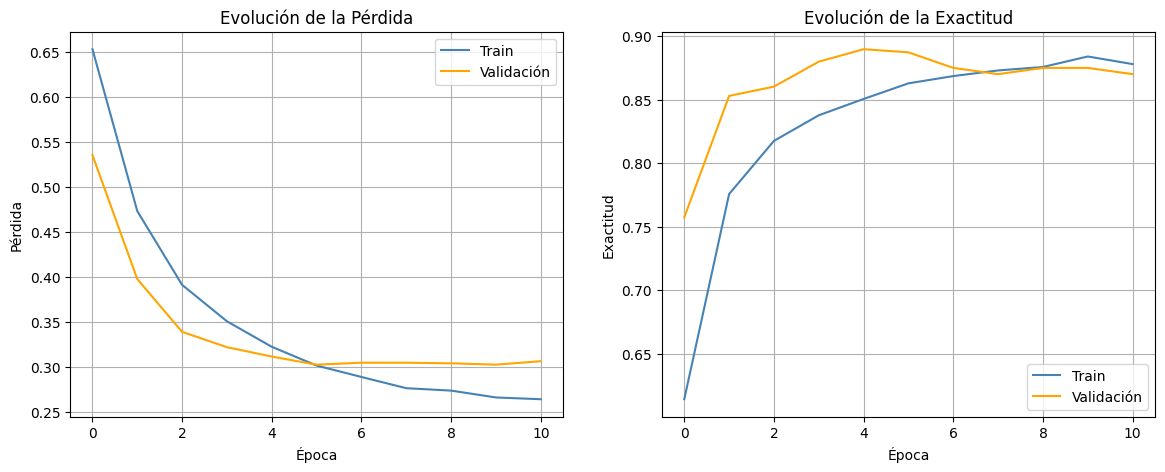

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss
ax1.plot(history.history['loss'], label='Train', color='steelblue')
ax1.plot(history.history['val_loss'], label='Validación', color='orange')
ax1.set_title('Evolución de la Pérdida')
ax1.set_xlabel('Época')
ax1.set_ylabel('Pérdida')
ax1.legend()
ax1.grid(True)

# Accuracy
ax2.plot(history.history['binary_accuracy'], label='Train', color='steelblue')
ax2.plot(history.history['val_binary_accuracy'], label='Validación', color='orange')
ax2.set_title('Evolución de la Exactitud')
ax2.set_xlabel('Época')
ax2.set_ylabel('Exactitud')
ax2.legend()
ax2.grid(True)

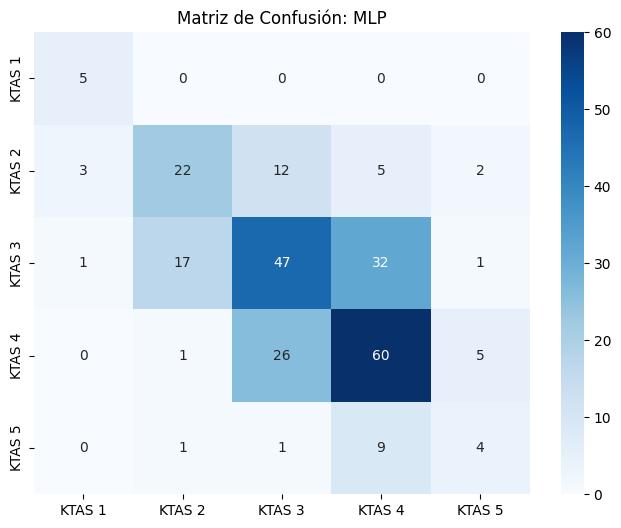

In [ ]:
cm_MLP = confusion_matrix(y_test_final_label, y_pred_ordinal)
plt.figure(figsize=(8,6))
sns.heatmap(cm_MLP, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f'KTAS {i+1}' for i in range(5)],
            yticklabels=[f'KTAS {i+1}' for i in range(5)])
plt.title('Matriz de Confusión: MLP')
plt.show()

## **Logistic Regression**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score

# ─────────────────────────────────────────────
# HIPERPARÁMETROS LR
# ─────────────────────────────────────────────
C             = 0.01       # Menor regularización, mejor resultado en experimentos
SOLVER        = 'lbfgs'    # Mejor resultado en experimentos
MAX_ITER      = 1000       # Suficiente para converger

# ─────────────────────────────────────────────
# MODELO
# ─────────────────────────────────────────────
lr_model = LogisticRegression(
    C=C,
    solver=SOLVER,
    penalty='l2',
    max_iter=MAX_ITER,
    random_state=42,
    multi_class='multinomial'
)

lr_model.fit(X_train_final, y_train_final_label)

# ─────────────────────────────────────────────
# EVALUACIÓN
# ─────────────────────────────────────────────
y_pred_lr = lr_model.predict(X_test_final)

y_proba_lr = lr_model.predict_proba(X_test_final)
aucs_lr = calcular_auc_por_clase(y_test_final_label, y_proba_lr)
print("\nLR AUC por clase:")
for k, v in aucs_lr.items():
    print(f"  {k}: {v}")

print(classification_report(y_test_final_label, y_pred_lr))
f1_macro = f1_score(y_test_final_label, y_pred_lr, average='macro')
print(f"F1 Macro: {f1_macro:.3f}")

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(



LR AUC por clase:
  AUC Clase 1: 0.996
  AUC Clase 2: 0.833
  AUC Clase 3: 0.781
  AUC Clase 4: 0.816
  AUC Clase 5: 0.742
  AUC Macro: 0.834
              precision    recall  f1-score   support

           1       0.62      1.00      0.77         5
           2       0.60      0.57      0.58        44
           3       0.62      0.54      0.58        98
           4       0.69      0.52      0.59        92
           5       0.14      0.47      0.22        15

    accuracy                           0.54       254
   macro avg       0.53      0.62      0.55       254
weighted avg       0.61      0.54      0.57       254

F1 Macro: 0.548


In [ ]:
# ─────────────────────────────────────────────
# TABLA RESUMEN ESTILO TUTOR
# ─────────────────────────────────────────────
from sklearn.metrics import accuracy_score

auc_macro = aucs_lr['AUC Macro']

tabla = []
for c in [1, 2, 3, 4, 5]:
    report = classification_report(y_test_final_label, y_pred_lr, output_dict=True, zero_division=0)
    tabla.append({
        'Clase': f'C{c}',
        'Precision': round(report[str(c)]['precision'], 3),
        'Recall':    round(report[str(c)]['recall'], 3),
        'F1-score':  round(report[str(c)]['f1-score'], 3),
        'AUC':       aucs_lr[f'AUC Clase {c}']
    })

df_tabla = pd.DataFrame(tabla)
print("\n===== TABLA RESULTADOS POR CLASE =====")
print(df_tabla.to_string(index=False))

print("\n===== MÉTRICAS GLOBALES =====")
print(f"Accuracy:    {round(accuracy_score(y_test_final_label, y_pred_lr), 3)}")
print(f"F1 Macro:    {round(f1_score(y_test_final_label, y_pred_lr, average='macro'), 3)}")
print(f"F1 Weighted: {round(f1_score(y_test_final_label, y_pred_lr, average='weighted'), 3)}")
print(f"AUC Macro:   {auc_macro}")


===== TABLA RESULTADOS POR CLASE =====
Clase  Precision  Recall  F1-score   AUC
   C1      0.625   1.000     0.769 0.996
   C2      0.595   0.568     0.581 0.833
   C3      0.624   0.541     0.579 0.781
   C4      0.686   0.522     0.593 0.816
   C5      0.143   0.467     0.219 0.742

===== MÉTRICAS GLOBALES =====
Accuracy:    0.543
F1 Macro:    0.548
F1 Weighted: 0.567
AUC Macro:   0.834


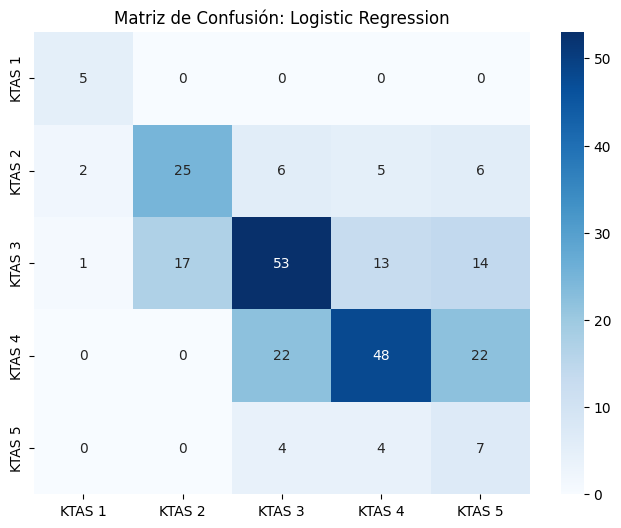

In [ ]:
cm_LR = confusion_matrix(y_test_final_label, y_pred_lr)
plt.figure(figsize=(8,6))
sns.heatmap(cm_LR, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f'KTAS {i+1}' for i in range(5)],
            yticklabels=[f'KTAS {i+1}' for i in range(5)])
plt.title('Matriz de Confusión: Logistic Regression')
plt.show()

## **XGBoost Manual**

In [ ]:
import xgboost as xgb
from sklearn.metrics import classification_report, f1_score

# ─────────────────────────────────────────────
# HIPERPARÁMETROS XGBOOST
# ─────────────────────────────────────────────
N_ESTIMATORS  = 719   # Más árboles mejora el resultado
MAX_DEPTH     = 5     # Profundidad óptima en experimentos
LEARNING_RATE = 0.01  # LR bajo: mejor F1 Macro y clase 1
SUBSAMPLE     = 0.8   # Porcentaje de datos por árbol
GAMMA         = 0.1     # Sin regularización adicional (gamma=0.1 destruía clase 1)
COLSAMPLE     = 0.8   # Porcentaje de variables por árbol
MIN_child_weight = 1

# ─────────────────────────────────────────────
# MODELO
# ─────────────────────────────────────────────
xgb_model = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=5,
    n_estimators=N_ESTIMATORS,
    max_depth=MAX_DEPTH,
    learning_rate=LEARNING_RATE,
    subsample=SUBSAMPLE,
    gamma=GAMMA,
    colsample_bytree=COLSAMPLE,
    min_child_weight = MIN_child_weight,
    eval_metric='mlogloss',
    early_stopping_rounds=15,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
        X_train_final,
        y_train_final_label - 1,
        eval_set=[(X_train_final, y_train_final_label - 1), (X_val_final, y_val_final_label - 1)],
        verbose=False
        )

# ─────────────────────────────────────────────
# EVALUACIÓN
# ─────────────────────────────────────────────
y_pred_xgb = xgb_model.predict(X_test_final) + 1

y_proba_xgb = xgb_model.predict_proba(X_test_final)
aucs_xgb = calcular_auc_por_clase(y_test_final_label, y_proba_xgb)
print("XGBoost AUC por clase:")
for k, v in aucs_xgb.items():
    print(f"  {k}: {v}")

print(classification_report(y_test_final_label, y_pred_xgb))
f1_macro = f1_score(y_test_final_label, y_pred_xgb, average='macro')
print(f"F1 Macro: {f1_macro:.3f}")

XGBoost AUC por clase:
  AUC Clase 1: 0.991
  AUC Clase 2: 0.831
  AUC Clase 3: 0.785
  AUC Clase 4: 0.828
  AUC Clase 5: 0.748
  AUC Macro: 0.836
              precision    recall  f1-score   support

           1       0.75      0.60      0.67         5
           2       0.60      0.61      0.61        44
           3       0.64      0.59      0.61        98
           4       0.64      0.66      0.65        92
           5       0.28      0.33      0.30        15

    accuracy                           0.61       254
   macro avg       0.58      0.56      0.57       254
weighted avg       0.61      0.61      0.61       254

F1 Macro: 0.568


In [ ]:
# ─────────────────────────────────────────────
# TABLA RESUMEN ESTILO TUTOR
# ─────────────────────────────────────────────
from sklearn.metrics import accuracy_score

auc_macro = aucs_xgb['AUC Macro']

tabla = []
for c in [1, 2, 3, 4, 5]:
    report = classification_report(y_test_final_label, y_pred_xgb, output_dict=True, zero_division=0)
    tabla.append({
        'Clase': f'{c}',
        'Precision': round(report[str(c)]['precision'], 3),
        'Recall':    round(report[str(c)]['recall'], 3),
        'F1-score':  round(report[str(c)]['f1-score'], 3),
        'AUC':       aucs_xgb[f'AUC Clase {c}']
    })

df_tabla = pd.DataFrame(tabla)
print("\n===== TABLA RESULTADOS POR CLASE =====")
print(df_tabla.to_string(index=False))

print("\n===== MÉTRICAS GLOBALES =====")
print(f"Accuracy:    {round(accuracy_score(y_test_final_label, y_pred_xgb), 3)}")
print(f"F1 Macro:    {round(f1_score(y_test_final_label, y_pred_xgb, average='macro'), 3)}")
print(f"F1 Weighted: {round(f1_score(y_test_final_label, y_pred_xgb, average='weighted'), 3)}")
print(f"AUC Macro:   {auc_macro}")


===== TABLA RESULTADOS POR CLASE =====
Clase  Precision  Recall  F1-score   AUC
    1      0.750   0.600     0.667 0.991
    2      0.600   0.614     0.607 0.831
    3      0.637   0.592     0.614 0.785
    4      0.635   0.663     0.649 0.828
    5      0.278   0.333     0.303 0.748

===== MÉTRICAS GLOBALES =====
Accuracy:    0.606
F1 Macro:    0.568
F1 Weighted: 0.608
AUC Macro:   0.836


In [ ]:
print(xgb_model.evals_result().keys())

dict_keys(['validation_0', 'validation_1'])


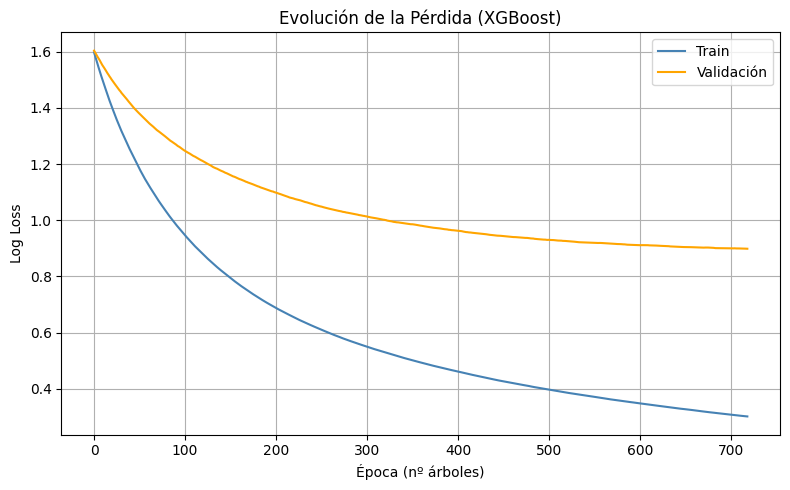

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(8, 5))

ax.plot(xgb_model.evals_result()['validation_0']['mlogloss'], label='Train', color='steelblue')
ax.plot(xgb_model.evals_result()['validation_1']['mlogloss'], label='Validación', color='orange')
ax.set_title('Evolución de la Pérdida (XGBoost)')
ax.set_xlabel('Época (nº árboles)')
ax.set_ylabel('Log Loss')
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()

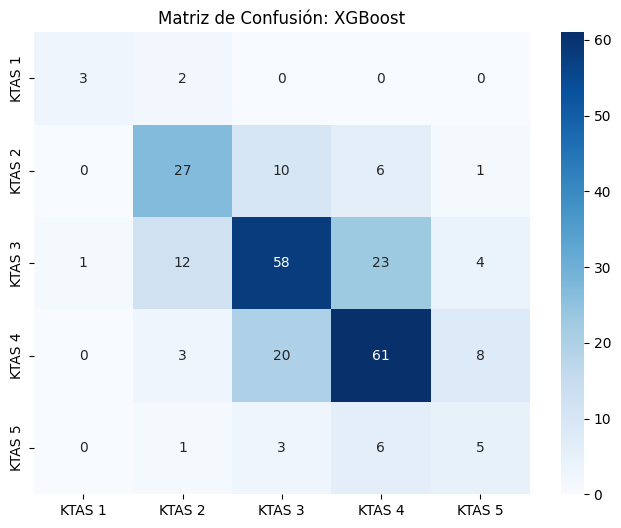

In [ ]:
cm_XGB = confusion_matrix(y_test_final_label, y_pred_xgb)
plt.figure(figsize=(8,6))
sns.heatmap(cm_XGB, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f'KTAS {i+1}' for i in range(5)],
            yticklabels=[f'KTAS {i+1}' for i in range(5)])
plt.title('Matriz de Confusión: XGBoost')
plt.show()

https://www.aprendemachinelearning.com/clasificacion-con-datos-desbalanceados/

In [ ]:
import pandas as pd
from sklearn.metrics import f1_score, accuracy_score

# Lista donde guardaremos todos los experimentos
resultados = []

def guardar_resultado(modelo, hiperparametros, y_true, y_pred, auc=None):
  report = classification_report(
        y_true,
        y_pred,
        output_dict=True,
        zero_division=0
    )

  """Guarda las métricas de un experimento"""
  resultados.append({
      'Modelo': modelo,
      **hiperparametros,  # desempaqueta los hiperparámetros como columnas
      'Accuracy': round(accuracy_score(y_true, y_pred), 3),
      'F1 Macro': round(f1_score(y_true, y_pred, average='macro'), 3),
      'F1 Weighted': round(f1_score(y_true, y_pred, average='weighted'), 3),
      'Precision C1': round(report['1']['precision'],3),
      'Recall C1': round(report['1']['recall'], 3),
      'F1 C1': round(report['1']['f1-score'], 3),
      'Precision C5': round(report['5']['precision'],3),
      'Recall C5': round(report['5']['recall'], 3),
      'F1 C5': round(report['5']['f1-score'], 3),
      'AUC': round(auc, 3) if auc is not None else None
  })

def mostrar_tabla(modelo):
    df = pd.DataFrame(resultados)
    df_modelo = df[df['Modelo'] == modelo].dropna(axis=1, how='all')
    print(f"\n{'='*60}")
    print(f"  Resultados {modelo}")
    print('='*60)
    print(df_modelo.to_string(index=False))

def ordinal_to_proba_5clases(probs_ordinal):
    p = np.zeros((len(probs_ordinal), 5))
    p[:, 0] = 1 - probs_ordinal[:, 0]
    p[:, 1] = probs_ordinal[:, 0] - probs_ordinal[:, 1]
    p[:, 2] = probs_ordinal[:, 1] - probs_ordinal[:, 2]
    p[:, 3] = probs_ordinal[:, 2] - probs_ordinal[:, 3]
    p[:, 4] = probs_ordinal[:, 3]
    p = np.clip(p, 0, 1)
    return p

def calcular_auc_por_clase(y_true, y_proba, clases=[1,2,3,4,5]):
    y_bin = label_binarize(y_true, classes=clases)
    aucs = {}
    for i, clase in enumerate(clases):
        auc = roc_auc_score(y_bin[:, i], y_proba[:, i])
        aucs[f'AUC Clase {clase}'] = round(auc, 3)
    aucs['AUC Macro'] = round(roc_auc_score(y_bin, y_proba, average='macro', multi_class='ovr'), 3)
    return aucs

# **DATASET B: Variables App**

In [ ]:
from sklearn.impute import KNNImputer
#definimos nuestras etiquetas y features
X_B = df_modelo[["Sex", "Age",
    "Injury", "Pain", "SBP", "DBP",
    "HR", "RR", "BT", "Saturation", "Mental"]]

#Añadir variables Chief_complain
X_completo = pd.concat([X_B.reset_index(drop=True),
                        df_motivos.reset_index(drop=True)], axis=1)

y = df['KTAS_expert']

#dividimos en sets de entrenamiento y test
X_train, X_test, y_train, y_test = train_test_split(X_completo, y, train_size=0.8, random_state=42, stratify=y)

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    train_size=0.9,
    random_state=42,
    stratify=y_train
)


In [ ]:
from sklearn.experimental import enable_iterative_imputer
from imblearn.over_sampling import SMOTE
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler

# Imputamos valores nulos (en lugar de borrar filas)
imputer = IterativeImputer(random_state=42, max_iter=10)

X_train_imp = imputer.fit_transform(X_train_sub)
X_val_imp = imputer.transform(X_val)
X_test_imp = imputer.transform(X_test) # Usamos el test original sin recortar

# ESCALADO (Vital para Redes Neuronales)
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imp)
X_val_final = scaler.transform(X_val_imp)
X_test_final = scaler.transform(X_test_imp)

# SMOTE (Balanceo Sintético) ---
# Esto crea los "pacientes sintéticos" para que todas las clases tengan el mismo peso
sm = SMOTE(random_state=42, k_neighbors=4)
X_train_final, y_train_res = sm.fit_resample(X_train_scaled, y_train_sub)


#Etiquetas ordinales para MLP
y_train_ordinal_bal = transform_to_ordinal(y_train_res)
y_val_ordinal = transform_to_ordinal(y_val)
y_test_ordinal = transform_to_ordinal(y_test)

#Etiquetas normales para LR y XGBoost
y_train_final_label = y_train_res
y_val_final_label = y_val
y_test_final_label = y_test

print("Train tras SMOTE:", X_train_final.shape)
print("Validación:", X_val_final.shape)
print("Test:", X_test_final.shape)


Train tras SMOTE: (1750, 20)
Validación: (102, 20)
Test: (254, 20)


/usr/local/lib/python3.12/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


# **Entrenamiento con Validation Data**



## **MLP Manual**

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import classification_report, f1_score, accuracy_score, roc_auc_score
from sklearn.preprocessing import label_binarize

resultados=[]
def entrenar_mlp(neuronas_1, neuronas_2, dropout, lr, activation ='relu', epochs=50, threshold=0.5):

    model = Sequential([
        Dense(neuronas_1, activation=activation, input_dim=X_train_final.shape[1]),
        Dropout(dropout),

        Dense(neuronas_2, activation=activation),
        Dropout(dropout),

        Dense(4, activation='sigmoid')
    ])

    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss='binary_crossentropy',
        metrics=['binary_accuracy']
    )

    early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

    history = model.fit(
        X_train_final, y_train_ordinal_bal,
        epochs=epochs,
        batch_size=32,
        validation_data=(X_val_final, y_val_ordinal),
        callbacks=[early_stop],
        verbose=0  # silencioso para no saturar la pantalla
    )

    probs = model.predict(X_val_final, verbose=0)
    y_pred = np.sum(probs > threshold, axis=1) + 1

    # AUC
    y_val_bin = label_binarize(y_val_final_label, classes=[1,2,3,4,5])
    probs_mlp = ordinal_to_proba_5clases(probs)
    auc = roc_auc_score(y_val_bin, probs_mlp, average='macro', multi_class='ovr')
    aucs = calcular_auc_por_clase(y_val_final_label, probs_mlp)

    epochs_reales = early_stop.stopped_epoch + 1 if early_stop.stopped_epoch > 0 else epochs

    guardar_resultado(
        modelo='MLP',
        hiperparametros={
            'Neuronas 1': neuronas_1,
            'Neuronas 2': neuronas_2,
            'Dropout': dropout,
            'LR': lr,
            'Activación': activation,
            'Epochs reales': epochs_reales
        },
        y_true=y_val_final_label,
        y_pred=y_pred,
        auc=auc,
        aucs_clase=aucs
    )
    print(f"Exp completado — Epochs reales: {epochs_reales}")

# Ejecutar todos los experimentos
# Arquitecturas base
entrenar_mlp(neuronas_1=32, neuronas_2=16, dropout=0.2, lr=0.001, activation='relu')   # Exp 1
entrenar_mlp(neuronas_1=32, neuronas_2=32, dropout=0.2, lr=0.001, activation='relu')   # Exp 2
entrenar_mlp(neuronas_1=64, neuronas_2=32, dropout=0.2, lr=0.001, activation='relu')   # Exp 3
entrenar_mlp(neuronas_1=64, neuronas_2=64, dropout=0.2, lr=0.001, activation='relu')   # Exp 4

# Dropout
entrenar_mlp(neuronas_1=64, neuronas_2=32, dropout=0.1, lr=0.001, activation='relu')   # Exp 5
entrenar_mlp(neuronas_1=64, neuronas_2=32, dropout=0.3, lr=0.001, activation='relu')   # Exp 6

# Learning rate
entrenar_mlp(neuronas_1=64, neuronas_2=32, dropout=0.2, lr=0.01,   activation='relu')   # Exp 7
entrenar_mlp(neuronas_1=64, neuronas_2=32, dropout=0.2, lr=0.0001, activation='relu')   # Exp 8

# Función de activación
entrenar_mlp(neuronas_1=64, neuronas_2=32, dropout=0.2, lr=0.001, activation='tanh')   # Exp 9

# Ver tabla comparativa en validación
mostrar_tabla('MLP')

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Exp completado — Epochs reales: 14


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Exp completado — Epochs reales: 50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


...

Exp completado — Epochs reales: 12


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Exp completado — Epochs reales: 45


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Exp completado — Epochs reales: 13

  Resultados MLP
Modelo  Neuronas 1  Neuronas 2  Dropout     LR Activación  Epochs reales  Accuracy  F1 Macro  F1 Weighted  Precision C1  Recall C1  F1 C1  AUC C1  Precision C5  Recall C5  F1 C5  AUC C5  AUC Macro
   MLP          32          16      0.2 0.0010       relu             14     0.559     0.480        0.543         0.500        1.0  0.667   0.995         0.000      0.000  0.000   0.648      0.782
   MLP          32          32      0.2 0.0010       relu             50     0.529     0.492        0.546         0.500        1.0  0.667   0.990         0.000      0.000  0.000   0.748      0.821
   MLP          64          32      0.2 0.0010       relu             26     0.471     0.449        0.484         0.500        1.0  0.667   0.995         0.000      0.000  0.000   0.703      0.799
   MLP          64          64      0.2 0.0010       relu              9     0.480     0.443        0.494         0.333        1.0  0.500   0.995         0.133

In [ ]:
entrenar_mlp(neuronas_1=32, neuronas_2=32, dropout=0.2, lr=0.001, activation='relu', epochs=80)
mostrar_tabla('MLP')

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Exp completado — Epochs reales: 15

  Resultados MLP
Modelo  Neuronas 1  Neuronas 2  Dropout     LR Activación  Epochs reales  Accuracy  F1 Macro  F1 Weighted  Precision C1  Recall C1  F1 C1  AUC C1  Precision C5  Recall C5  F1 C5  AUC C5  AUC Macro
   MLP          32          16      0.2 0.0010       relu             14     0.559     0.480        0.543         0.500        1.0  0.667   0.995         0.000      0.000  0.000   0.648      0.782
   MLP          32          32      0.2 0.0010       relu             50     0.529     0.492        0.546         0.500        1.0  0.667   0.990         0.000      0.000  0.000   0.748      0.821
   MLP          64          32      0.2 0.0010       relu             26     0.471     0.449        0.484         0.500        1.0  0.667   0.995         0.000      0.000  0.000   0.703      0.799
   MLP          64          64      0.2 0.0010       relu              9     0.480     0.443        0.494         0.333        1.0  0.500   0.995         0.133

## **Logistic Regression**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score

resultados=[]
def entrenar_lr(C, solver):
    model = LogisticRegression(
        C=C,
        solver=solver,
        max_iter=1000,
        random_state=42,
        multi_class='multinomial'
    )

    model.fit(X_train_final, y_train_final_label)
    y_pred = model.predict(X_val_final)

    y_val_bin = label_binarize(y_val_final_label, classes=[1,2,3,4,5])
    probs_lr = model.predict_proba(X_val_final)
    auc = roc_auc_score(y_val_bin, probs_lr, average='macro', multi_class='ovr')
    aucs = calcular_auc_por_clase(y_val_final_label, probs_lr)

    guardar_resultado(
        modelo='LR',
        hiperparametros={
            'C': C,
            'Solver': solver,
        },
        y_true=y_val_final_label,
        y_pred=y_pred,
        auc=auc,
        aucs_clase=aucs
    )
    print(f"Exp completado — C={C}, solver={solver}")

# Ejecutar experimentos
entrenar_lr(C=0.01, solver='lbfgs')
entrenar_lr(C=0.1,  solver='lbfgs')
entrenar_lr(C=1,    solver='lbfgs')
entrenar_lr(C=10,   solver='lbfgs')
entrenar_lr(C=100,  solver='lbfgs')

entrenar_lr(C=0.01, solver='newton-cg')
entrenar_lr(C=0.1,  solver='newton-cg')
entrenar_lr(C=1,    solver='newton-cg')
entrenar_lr(C=10,   solver='newton-cg')
entrenar_lr(C=100,  solver='newton-cg')

# Ver tabla
mostrar_tabla('LR')

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Exp completado — C=0.01, solver=lbfgs
Exp completado — C=0.1, solver=lbfgs
Exp completado — C=1, solver=lbfgs


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Exp completado — C=10, solver=lbfgs
Exp completado — C=100, solver=lbfgs


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Exp completado — C=0.01, solver=newton-cg
Exp completado — C=0.1, solver=newton-cg
Exp completado — C=1, solver=newton-cg


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Exp completado — C=10, solver=newton-cg
Exp completado — C=100, solver=newton-cg

  Resultados LR
Modelo      C    Solver  Accuracy  F1 Macro  F1 Weighted  Precision C1  Recall C1  F1 C1  AUC C1  Precision C5  Recall C5  F1 C5  AUC C5  AUC Macro
    LR   0.01     lbfgs     0.461     0.431        0.492         0.333        1.0  0.500     1.0         0.087      0.333  0.138   0.701      0.799
    LR   0.10     lbfgs     0.451     0.443        0.484         0.400        1.0  0.571     1.0         0.083      0.333  0.133   0.675      0.789
    LR   1.00     lbfgs     0.441     0.438        0.475         0.400        1.0  0.571     1.0         0.080      0.333  0.129   0.668      0.784
    LR  10.00     lbfgs     0.441     0.438        0.475         0.400        1.0  0.571     1.0         0.080      0.333  0.129   0.668      0.782
    LR 100.00     lbfgs     0.431     0.432        0.464         0.400        1.0  0.571     1.0         0.080      0.333  0.129   0.667      0.781
    LR   0.01 

## **XGBoost**

In [ ]:
import xgboost as xgb

resultados=[]
def entrenar_xgb(max_depth, learning_rate, subsample, gamma, colsample_bytree= 0.8, min_child_weight=1,):
    model = xgb.XGBClassifier(
        objective='multi:softprob',
        num_class=5,
        n_estimators=1000,
        max_depth=max_depth,
        learning_rate=learning_rate,
        subsample=subsample,
        gamma=gamma,
        colsample_bytree=colsample_bytree,
        min_child_weight=min_child_weight,
        eval_metric="mlogloss",
        early_stopping_rounds=15,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_train_final,
        y_train_final_label - 1,
        eval_set=[(X_val_final, y_val_final_label - 1)],
        verbose=False
    )
    y_pred = model.predict(X_val_final) + 1

    y_val_bin = label_binarize(y_val_final_label, classes=[1,2,3,4,5])
    probs_xgb = model.predict_proba(X_val_final)
    auc = roc_auc_score(y_val_bin, probs_xgb, average='macro', multi_class='ovr')
    aucs = calcular_auc_por_clase(y_val_final_label, probs_xgb)

    guardar_resultado(
        modelo='XGBoost',
        hiperparametros={
            'Max depth': max_depth,
            'Learning rate': learning_rate,
            'Subsample': subsample,
            'Gamma': gamma,
            'Colsample': colsample_bytree,
            'Min child weight': min_child_weight,
            'Best iteration': model.best_iteration + 1
        },
        y_true=y_val_final_label,
        y_pred=y_pred,
        auc=auc,
        aucs_clase=aucs
    )
    print(f"Exp completado — best_iteration={model.best_iteration + 1}, max_depth={max_depth}, lr={learning_rate}")

# BASELINE
entrenar_xgb(
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    gamma=0
)

# DEPTH
entrenar_xgb(
    max_depth=3,
    learning_rate=0.1,
    subsample=0.8,
    gamma=0
)

entrenar_xgb(
    max_depth=7,
    learning_rate=0.1,
    subsample=0.8,
    gamma=0
)

# LEARNING RATE
entrenar_xgb(
    max_depth=5,
    learning_rate=0.01,
    subsample=0.8,
    gamma=0
)

# SUBSAMPLE
entrenar_xgb(
    max_depth=5,
    learning_rate=0.1,
    subsample=0.6,
    gamma=0
)

# GAMMA
entrenar_xgb(
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    gamma=0.1
)

mostrar_tabla('XGBoost')

Exp completado — best_iteration=82, max_depth=5, lr=0.1
Exp completado — best_iteration=152, max_depth=3, lr=0.1
Exp completado — best_iteration=53, max_depth=7, lr=0.1
Exp completado — best_iteration=700, max_depth=5, lr=0.01
Exp completado — best_iteration=76, max_depth=5, lr=0.1
Exp completado — best_iteration=79, max_depth=5, lr=0.1

  Resultados XGBoost
 Modelo  Max depth  Learning rate  Subsample  Gamma  Colsample  Min child weight  Best iteration  Accuracy  F1 Macro  F1 Weighted  Precision C1  Recall C1  F1 C1  AUC C1  Precision C5  Recall C5  F1 C5  AUC C5  AUC Macro
XGBoost          5           0.10        0.8    0.0        0.8                 1              82     0.559     0.612        0.558           1.0        1.0    1.0     1.0         0.333      0.333  0.333   0.675      0.818
XGBoost          3           0.10        0.8    0.0        0.8                 1             152     0.588     0.630        0.589           1.0        1.0    1.0     1.0         0.333      0.333  0

# **Entrenamiento Final**

## **MLP**

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, f1_score
import numpy as np

# ─────────────────────────────────────────────
# HIPERPARÁMETROS
# ─────────────────────────────────────────────

N_INPUT      = X_train_final.shape[1]  # Neuronas capa 1 = variables de entrada
UNITS_1      = 64                #
UNITS_2      = 32                     # Neuronas capa 2: prueba 32, 64, 128
ACTIVATION   = 'relu'
DROPOUT       = 0.1                       # Regularización capa 1: prueba 0.2, 0.3, 0.5                    # Regularización capa 2
LEARNING_RATE = 0.01                  # Prueba 0.01, 0.001, 0.0001
BATCH_SIZE   = 32                      # Prueba 16, 32, 64
EPOCHS       = 50                      # Con EarlyStopping no importa poner un número alto
THRESHOLD    = 0.5                     # Umbral para convertir probabilidades a clase ordinal

# ─────────────────────────────────────────────
# MODELO
# ─────────────────────────────────────────────

model = Sequential([
    # Capa 1: igual al número de variables de entrada
    Dense(UNITS_1, activation=ACTIVATION, input_dim=N_INPUT),
    Dropout(DROPOUT),

    # Capa 2: normalmente la mitad o igual que la capa 1
    Dense(UNITS_2, activation=ACTIVATION),
    Dropout(DROPOUT),

    # Salida ordinal: 4 neuronas (n_clases - 1), sigmoid
    Dense(4, activation='sigmoid')
])

model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='binary_crossentropy',
    metrics=['binary_accuracy']
)

model.summary()  # Comprueba aquí que la primera capa tiene 10 neuronas

# ─────────────────────────────────────────────
# ENTRENAMIENTO
# ─────────────────────────────────────────────

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,               # Con 50 epochs, patience=10 es más razonable que 7
    restore_best_weights=True
)

history = model.fit(
    X_train_final, y_train_ordinal_bal,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val_final, y_val_ordinal),
    callbacks=[early_stop],
    verbose=1
)

print(f"El modelo paró en el epoch: {early_stop.stopped_epoch + 1}")

# ─────────────────────────────────────────────
# EVALUACIÓN
# ─────────────────────────────────────────────

probs = model.predict(X_test_final)
y_pred_ordinal = np.sum(probs > THRESHOLD, axis=1) + 1

y_proba_mlp = ordinal_to_proba_5clases(probs)
aucs_mlp = calcular_auc_por_clase(y_test_final_label, y_proba_mlp)
print("\nMLP AUC por clase:")
for k, v in aucs_mlp.items():
    print(f"  {k}: {v}")

print(classification_report(y_test_final_label, y_pred_ordinal))

# Métrica macro como resumen justo entre clases
f1_macro = f1_score(y_test_final_label, y_pred_ordinal, average='macro')
print(f"F1 Macro (trata todas las clases por igual): {f1_macro:.3f}")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 64)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,556 (13.89 KB)

 Trainable params: 3,556 (13.89 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - binary_accuracy: 0.8563 - loss: 0.3249 - val_binary_accuracy: 0.8284 - val_loss: 0.3392
Epoch 2/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.8924 - loss: 0.2422 - val_binary_accuracy: 0.8309 - val_loss: 0.3670
Epoch 3/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9029 - loss: 0.2197 - val_binary_accuracy: 0.8333 - val_loss: 0.3485
Epoch 4/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9103 - loss: 0.2035 - val_binary_accuracy: 0.8431 - val_loss: 0.3562
Epoch 5/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9147 - loss: 0.1924 - val_binary_accuracy: 0.8456 - val_loss: 0.3460
Epoch 6/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9237 - loss: 0.1803 - val_binary_accuracy: 0.8431 - val_loss: 0.3459
El modelo paró en el epoch: 6
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 

MLP AUC por clase:
  AUC Clase 1: 0.998
  AUC Clase 2: 0.815
  AUC Clase 3: 0.7
  AUC Clase

In [ ]:
# ─────────────────────────────────────────────
# TABLA RESUMEN ESTILO TUTOR
# ─────────────────────────────────────────────
from sklearn.metrics import accuracy_score

auc_macro = aucs_mlp['AUC Macro']

tabla = []
for c in [1, 2, 3, 4, 5]:
    report = classification_report(y_test_final_label, y_pred_ordinal, output_dict=True, zero_division=0)
    tabla.append({
        'Clase': f'{c}',
        'Precision': round(report[str(c)]['precision'], 3),
        'Recall':    round(report[str(c)]['recall'], 3),
        'F1-score':  round(report[str(c)]['f1-score'], 3),
        'AUC':       aucs_mlp[f'AUC Clase {c}']
    })

df_tabla = pd.DataFrame(tabla)
print("\n===== TABLA RESULTADOS POR CLASE =====")
print(df_tabla.to_string(index=False))

print("\n===== MÉTRICAS GLOBALES =====")
print(f"Accuracy:    {round(accuracy_score(y_test_final_label, y_pred_ordinal), 3)}")
print(f"F1 Macro:    {round(f1_score(y_test_final_label, y_pred_ordinal, average='macro'), 3)}")
print(f"F1 Weighted: {round(f1_score(y_test_final_label, y_pred_ordinal, average='weighted'), 3)}")
print(f"AUC Macro:   {auc_macro}")


===== TABLA RESULTADOS POR CLASE =====
Clase  Precision  Recall  F1-score   AUC
    1      0.625   1.000     0.769 0.998
    2      0.556   0.455     0.500 0.815
    3      0.542   0.459     0.497 0.700
    4      0.533   0.533     0.533 0.799
    5      0.143   0.333     0.200 0.727

===== MÉTRICAS GLOBALES =====
Accuracy:    0.488
F1 Macro:    0.5
F1 Weighted: 0.498
AUC Macro:   0.808


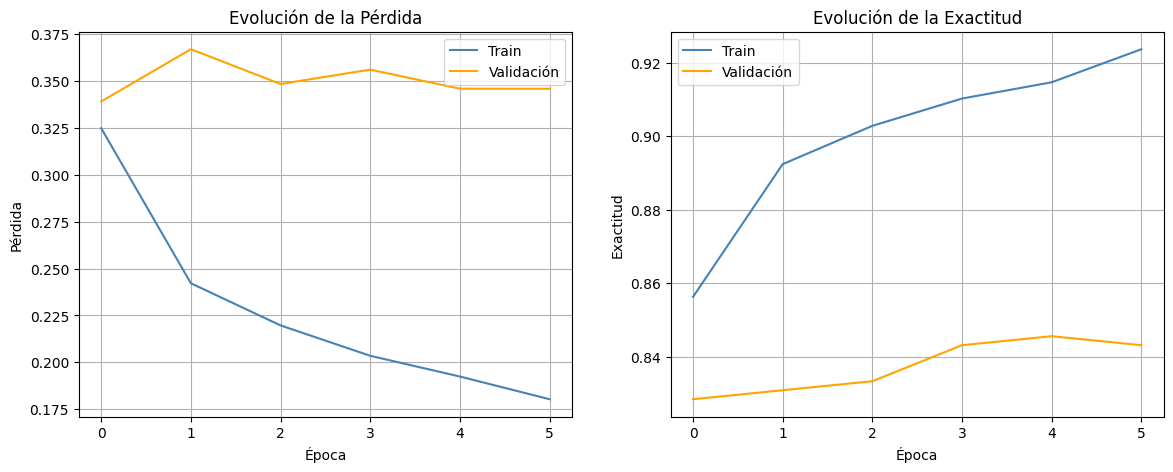

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss
ax1.plot(history.history['loss'], label='Train', color='steelblue')
ax1.plot(history.history['val_loss'], label='Validación', color='orange')
ax1.set_title('Evolución de la Pérdida')
ax1.set_xlabel('Época')
ax1.set_ylabel('Pérdida')
ax1.legend()
ax1.grid(True)

# Accuracy
ax2.plot(history.history['binary_accuracy'], label='Train', color='steelblue')
ax2.plot(history.history['val_binary_accuracy'], label='Validación', color='orange')
ax2.set_title('Evolución de la Exactitud')
ax2.set_xlabel('Época')
ax2.set_ylabel('Exactitud')
ax2.legend()
ax2.grid(True)

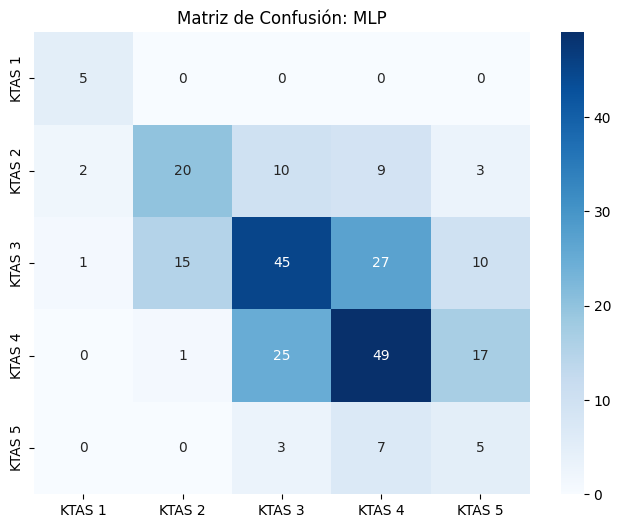

In [ ]:
cm_MLP = confusion_matrix(y_test_final_label, y_pred_ordinal)
plt.figure(figsize=(8,6))
sns.heatmap(cm_MLP, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f'KTAS {i+1}' for i in range(5)],
            yticklabels=[f'KTAS {i+1}' for i in range(5)])
plt.title('Matriz de Confusión: MLP')
plt.show()

##**Logistic Regression**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score

# ─────────────────────────────────────────────
# HIPERPARÁMETROS LR
# ─────────────────────────────────────────────
C             = 0.01       # Menor regularización, mejor resultado en experimentos
SOLVER        = 'lbfgs'    # Mejor resultado en experimentos
MAX_ITER      = 1000       # Suficiente para converger

# ─────────────────────────────────────────────
# MODELO
# ─────────────────────────────────────────────
lr_model = LogisticRegression(
    C=C,
    solver=SOLVER,
    max_iter=MAX_ITER,
    random_state=42,
    multi_class='multinomial'
)

lr_model.fit(X_train_final, y_train_final_label)

# ─────────────────────────────────────────────
# EVALUACIÓN
# ─────────────────────────────────────────────
y_pred_lr = lr_model.predict(X_test_final)

y_proba_lr = lr_model.predict_proba(X_test_final)
aucs_lr = calcular_auc_por_clase(y_test_final_label, y_proba_lr)
print("\nLR AUC por clase:")
for k, v in aucs_lr.items():
    print(f"  {k}: {v}")

print(classification_report(y_test_final_label, y_pred_lr))
f1_macro = f1_score(y_test_final_label, y_pred_lr, average='macro')
print(f"F1 Macro: {f1_macro:.3f}")


LR AUC por clase:
  AUC Clase 1: 0.996
  AUC Clase 2: 0.833
  AUC Clase 3: 0.761
  AUC Clase 4: 0.814
  AUC Clase 5: 0.71
  AUC Macro: 0.823
              precision    recall  f1-score   support

           1       0.62      1.00      0.77         5
           2       0.53      0.52      0.53        44
           3       0.59      0.49      0.53        98
           4       0.71      0.53      0.61        92
           5       0.15      0.53      0.24        15

    accuracy                           0.52       254
   macro avg       0.52      0.62      0.54       254
weighted avg       0.60      0.52      0.55       254

F1 Macro: 0.536


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [ ]:
# ─────────────────────────────────────────────
# TABLA RESUMEN ESTILO TUTOR
# ─────────────────────────────────────────────
from sklearn.metrics import accuracy_score

auc_macro = aucs_lr['AUC Macro']

tabla = []
for c in [1, 2, 3, 4, 5]:
    report = classification_report(y_test_final_label, y_pred_lr, output_dict=True, zero_division=0)
    tabla.append({
        'Clase': f'{c}',
        'Precision': round(report[str(c)]['precision'], 3),
        'Recall':    round(report[str(c)]['recall'], 3),
        'F1-score':  round(report[str(c)]['f1-score'], 3),
        'AUC':       aucs_lr[f'AUC Clase {c}']
    })

df_tabla = pd.DataFrame(tabla)
print("\n===== TABLA RESULTADOS POR CLASE =====")
print(df_tabla.to_string(index=False))

print("\n===== MÉTRICAS GLOBALES =====")
print(f"Accuracy:    {round(accuracy_score(y_test_final_label, y_pred_lr), 3)}")
print(f"F1 Macro:    {round(f1_score(y_test_final_label, y_pred_lr, average='macro'), 3)}")
print(f"F1 Weighted: {round(f1_score(y_test_final_label, y_pred_lr, average='weighted'), 3)}")
print(f"AUC Macro:   {auc_macro}")


===== TABLA RESULTADOS POR CLASE =====
Clase  Precision  Recall  F1-score   AUC
    1      0.625   1.000     0.769 0.996
    2      0.535   0.523     0.529 0.833
    3      0.585   0.490     0.533 0.761
    4      0.710   0.533     0.609 0.814
    5      0.154   0.533     0.239 0.710

===== MÉTRICAS GLOBALES =====
Accuracy:    0.524
F1 Macro:    0.536
F1 Weighted: 0.547
AUC Macro:   0.823


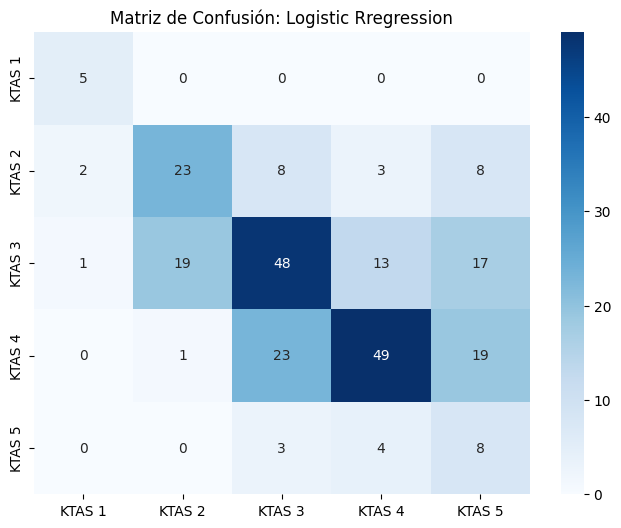

In [ ]:
cm_lr = confusion_matrix(y_test_final_label, y_pred_lr)
plt.figure(figsize=(8,6))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f'KTAS {i+1}' for i in range(5)],
            yticklabels=[f'KTAS {i+1}' for i in range(5)])
plt.title('Matriz de Confusión: Logistic Rregression')
plt.show()

## **XGBoost Manual**

In [ ]:
import xgboost as xgb
from sklearn.metrics import classification_report, f1_score

# ─────────────────────────────────────────────
# HIPERPARÁMETROS XGBOOST
# ─────────────────────────────────────────────
N_ESTIMATORS  = 76  # Más árboles mejora el resultado
MAX_DEPTH     = 5     # Profundidad óptima en experimentos
LEARNING_RATE = 0.1  # LR bajo: mejor F1 Macro y clase 1
SUBSAMPLE     = 0.6   # Porcentaje de datos por árbol
GAMMA         = 0     # Sin regularización adicional (gamma=0.1 destruía clase 1)
COLSAMPLE     = 0.8   # Porcentaje de variables por árbol
MIN_CHILD_WEIGHT  = 1

# ─────────────────────────────────────────────
# MODELO
# ─────────────────────────────────────────────
xgb_model = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=5,
    n_estimators=N_ESTIMATORS,
    max_depth=MAX_DEPTH,
    learning_rate=LEARNING_RATE,
    subsample=SUBSAMPLE,
    gamma=GAMMA,
    colsample_bytree=COLSAMPLE,
    min_child_weight = MIN_CHILD_WEIGHT,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
        X_train_final,
        y_train_final_label - 1,
        eval_set=[(X_train_final, y_train_final_label - 1),(X_val_final, y_val_final_label - 1)],
        verbose=False
    )
# ─────────────────────────────────────────────
# EVALUACIÓN
# ─────────────────────────────────────────────
y_pred_xgb = xgb_model.predict(X_test_final) + 1

y_proba_xgb = xgb_model.predict_proba(X_test_final)
aucs_xgb = calcular_auc_por_clase(y_test_final_label, y_proba_xgb)
print("XGBoost AUC por clase:")
for k, v in aucs_xgb.items():
    print(f"  {k}: {v}")

print(classification_report(y_test_final_label, y_pred_xgb))
f1_macro = f1_score(y_test_final_label, y_pred_xgb, average='macro')
print(f"F1 Macro: {f1_macro:.3f}")

XGBoost AUC por clase:
  AUC Clase 1: 0.977
  AUC Clase 2: 0.831
  AUC Clase 3: 0.778
  AUC Clase 4: 0.834
  AUC Clase 5: 0.688
  AUC Macro: 0.821
              precision    recall  f1-score   support

           1       0.75      0.60      0.67         5
           2       0.60      0.55      0.57        44
           3       0.64      0.64      0.64        98
           4       0.66      0.62      0.64        92
           5       0.24      0.40      0.30        15

    accuracy                           0.60       254
   macro avg       0.58      0.56      0.56       254
weighted avg       0.62      0.60      0.61       254

F1 Macro: 0.564


In [ ]:
# ─────────────────────────────────────────────
# TABLA RESUMEN ESTILO TUTOR
# ─────────────────────────────────────────────
from sklearn.metrics import accuracy_score

auc_macro = aucs_xgb['AUC Macro']

tabla = []
for c in [1, 2, 3, 4, 5]:
    report = classification_report(y_test_final_label, y_pred_xgb, output_dict=True, zero_division=0)
    tabla.append({
        'Clase': f'{c}',
        'Precision': round(report[str(c)]['precision'], 3),
        'Recall':    round(report[str(c)]['recall'], 3),
        'F1-score':  round(report[str(c)]['f1-score'], 3),
        'AUC':       aucs_xgb[f'AUC Clase {c}']
    })

df_tabla = pd.DataFrame(tabla)
print("\n===== TABLA RESULTADOS POR CLASE =====")
print(df_tabla.to_string(index=False))

print("\n===== MÉTRICAS GLOBALES =====")
print(f"Accuracy:    {round(accuracy_score(y_test_final_label, y_pred_xgb), 3)}")
print(f"F1 Macro:    {round(f1_score(y_test_final_label, y_pred_xgb, average='macro'), 3)}")
print(f"F1 Weighted: {round(f1_score(y_test_final_label, y_pred_xgb, average='weighted'), 3)}")
print(f"AUC Macro:   {auc_macro}")


===== TABLA RESULTADOS POR CLASE =====
Clase  Precision  Recall  F1-score   AUC
    1      0.750   0.600     0.667 0.977
    2      0.600   0.545     0.571 0.831
    3      0.643   0.643     0.643 0.778
    4      0.655   0.620     0.637 0.834
    5      0.240   0.400     0.300 0.688

===== MÉTRICAS GLOBALES =====
Accuracy:    0.602
F1 Macro:    0.564
F1 Weighted: 0.609
AUC Macro:   0.821


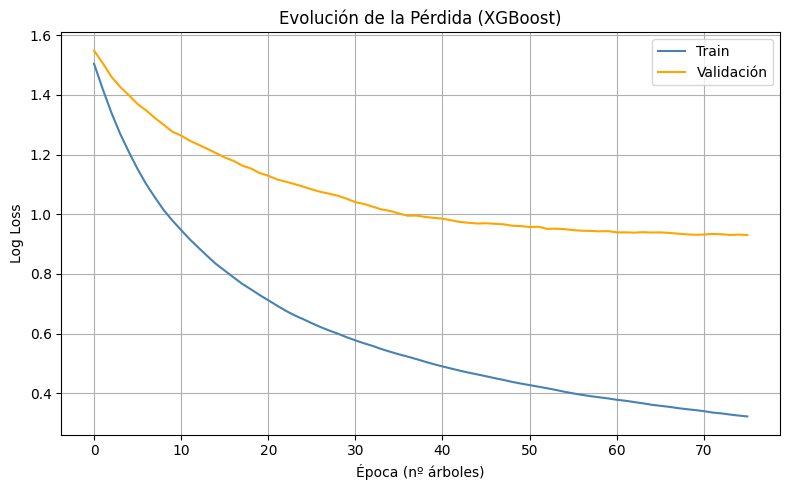

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(8, 5))

ax.plot(xgb_model.evals_result()['validation_0']['mlogloss'], label='Train', color='steelblue')
ax.plot(xgb_model.evals_result()['validation_1']['mlogloss'], label='Validación', color='orange')
ax.set_title('Evolución de la Pérdida (XGBoost)')
ax.set_xlabel('Época (nº árboles)')
ax.set_ylabel('Log Loss')
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()

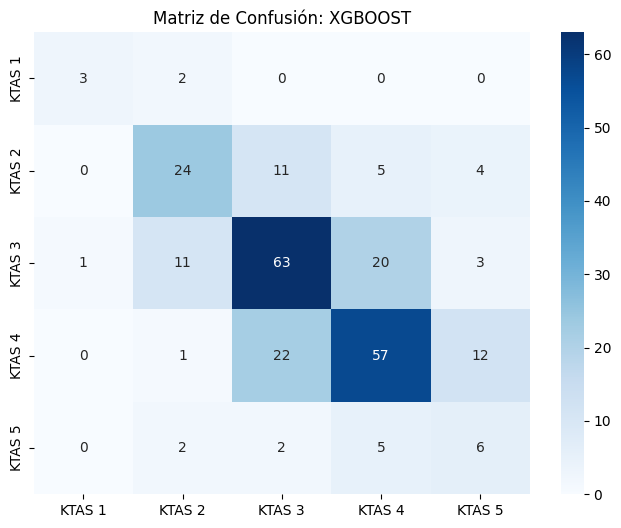

In [ ]:
cm_XGB = confusion_matrix(y_test_final_label, y_pred_xgb)
plt.figure(figsize=(8,6))
sns.heatmap(cm_XGB, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f'KTAS {i+1}' for i in range(5)],
            yticklabels=[f'KTAS {i+1}' for i in range(5)])
plt.title('Matriz de Confusión: XGBOOST')
plt.show()

# ***Agrupación Clases**

Crítico (clases 1+2)

Urgente (clase 3)

No urgente (clases 4+5)

In [ ]:
from sklearn.impute import KNNImputer
#definimos nuestras etiquetas y features
X_C = df_modelo[["Sex", "Age",
    "Injury", "Pain", "SBP", "DBP",
    "HR", "RR", "BT", "Saturation", "Mental"]]

#Añadir variables Chief_complain
X_completo_C = pd.concat([X_C.reset_index(drop=True),
                        df_motivos.reset_index(drop=True)], axis=1)

#--- AGRUPACIÓN CLÍNICA (3 CLASES) ---
# 1-2: Emergencia | 3: Urgencia | 4-5: No Urgente
map = {1: 1, 2: 1, 3: 2, 4: 3, 5: 3}

y = df['KTAS_expert'].map(map)

#dividimos en sets de entrenamiento y test
X_train, X_test, y_train, y_test = train_test_split(X_completo_C, y, train_size=0.8, random_state=42, stratify=y)

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    train_size=0.9,
    random_state=42,
    stratify=y_train
)

In [ ]:
# Función para ver representación de clases
def resumen_clases(y, nombre):
    resumen = pd.DataFrame({
        "n": y.value_counts().sort_index(),
        "%": (y.value_counts(normalize=True).sort_index() * 100).round(2)
    })
    print(f"\n{nombre}")
    print(resumen)

# Ver distribución de clases
resumen_clases(y, "Dataset completo")
resumen_clases(y_train, "Train inicial 80%")
resumen_clases(y_test, "Test 20%")
resumen_clases(y_train_sub, "Train_sub 90% del train")
resumen_clases(y_val, "Validación 10% del train")

# Ver tamaños finales
print("\nTamaños:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("X_train_sub:", X_train_sub.shape)
print("X_val:", X_val.shape)


Dataset completo
               n      %
KTAS_expert            
1            246  19.42
2            487  38.44
3            534  42.15

Train inicial 80%
               n      %
KTAS_expert            
1            197  19.45
2            389  38.40
3            427  42.15

Test 20%
               n      %
KTAS_expert            
1             49  19.29
2             98  38.58
3            107  42.13

Train_sub 90% del train
               n      %
KTAS_expert            
1            177  19.43
2            350  38.42
3            384  42.15

Validación 10% del train
              n      %
KTAS_expert           
1            20  19.61
2            39  38.24
3            43  42.16

Tamaños:
X_train: (1013, 20)
X_test: (254, 20)
X_train_sub: (911, 20)
X_val: (102, 20)


In [ ]:
feature_names = X_train_sub.columns.tolist()
print(feature_names)

['Sex', 'Age', 'Injury', 'Pain', 'SBP', 'DBP', 'HR', 'RR', 'BT', 'Saturation', 'Mental', 'Abdominal_Grave', 'Alteracion_Conciencia', 'Cardiovascular_Agudo', 'Cefalea_Mareo', 'Dificultad_Respiratoria', 'Infeccioso_Fiebre', 'Neurologico_Ictus', 'Otros_Sintomas', 'Trauma_Accidente']


In [ ]:
def transform_to_ordinal(y):
    """
    Transforma etiquetas de clase (1, 2, 3) en una matriz ordinal
    para una salida de 2 neuronas con activación sigmoide.

    Ejemplo:
    Clase 1 -> [0, 0]
    Clase 2 -> [1, 0]
    Clase 3 -> [1, 1]
    """
    # Comparamos cada valor de y con los umbrales 1, 2
    return np.array([[1 if y_val > i else 0 for i in range(1, 3)] for y_val in y])

In [ ]:
from sklearn.experimental import enable_iterative_imputer
from imblearn.over_sampling import SMOTE
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler

# Imputamos valores nulos (en lugar de borrar filas)
imputer = IterativeImputer(random_state=42, max_iter=10)

X_train_imp = imputer.fit_transform(X_train_sub)
X_val_imp = imputer.transform(X_val)
X_test_imp = imputer.transform(X_test) # Usamos el test original sin recortar

# ESCALADO (Vital para Redes Neuronales)
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imp)
X_val_final = scaler.transform(X_val_imp)
X_test_final = scaler.transform(X_test_imp)

# SMOTE (Balanceo Sintético) ---
# Esto crea los "pacientes sintéticos" para que todas las clases tengan el mismo peso
sm = SMOTE(random_state=42, k_neighbors=4)
X_train_final, y_train_res = sm.fit_resample(X_train_scaled, y_train_sub)


#Etiquetas ordinales para MLP
y_train_ordinal_bal = transform_to_ordinal(y_train_res)
y_val_ordinal = transform_to_ordinal(y_val)
y_test_ordinal = transform_to_ordinal(y_test)

#Etiquetas normales para LR y XGBoost
y_train_final_label = y_train_res
y_val_final_label = y_val
y_test_final_label = y_test

print("Train tras SMOTE:", X_train_final.shape)
print("Validación:", X_val_final.shape)
print("Test:", X_test_final.shape)


Train tras SMOTE: (1152, 20)
Validación: (102, 20)
Test: (254, 20)


/usr/local/lib/python3.12/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


In [ ]:
from collections import Counter
print("Distribución tras SMOTE:", Counter(y_train_final_label))

Distribución tras SMOTE: Counter({1: 384, 3: 384, 2: 384})


## **MLP Manual**

In [ ]:
import pandas as pd
from sklearn.metrics import f1_score, accuracy_score

# Lista donde guardaremos todos los experimentos
resultados = []

def guardar_resultado(modelo, hiperparametros, y_true, y_pred, auc=None, aucs_clase=None):
    report = classification_report(
        y_true,
        y_pred,
        output_dict=True,
        zero_division=0
    )
    resultados.append({
        'Modelo': modelo,
        **hiperparametros,  # desempaqueta los hiperparámetros como columnas
        'Accuracy': round(accuracy_score(y_true, y_pred), 3),
        'F1 Macro': round(f1_score(y_true, y_pred, average='macro'), 3),
        'F1 Weighted': round(f1_score(y_true, y_pred, average='weighted'), 3),
        'Precision C1': round(report['1']['precision'], 3),
        'Recall C1': round(report['1']['recall'],3),
        'F1 C1': round(report['1']['f1-score'], 3),
        'AUC C1': round(aucs_clase['AUC Clase 1'], 3) if aucs_clase else None,  #

        'Precision C3': round(report['3']['precision'],3),
        'Recall C3': round(report['3']['recall'],3),
        'F1 C3': round(report['3']['f1-score'],3),
        'AUC C3': round(aucs_clase['AUC Clase 3'], 3) if aucs_clase else None,  #

        'AUC Macro': round(auc, 3) if auc is not None else None
    })

def mostrar_tabla(modelo):
    df = pd.DataFrame(resultados)
    df_modelo = df[df['Modelo'] == modelo].dropna(axis=1, how='all')
    print(f"\n{'='*60}")
    print(f"  Resultados {modelo}")
    print('='*60)
    print(df_modelo.to_string(index=False))

def ordinal_to_proba_3clases(probs_ordinal):
    p = np.zeros((len(probs_ordinal), 3))
    p[:, 0] = 1 - probs_ordinal[:, 0]
    p[:, 1] = probs_ordinal[:, 0] - probs_ordinal[:, 1]
    p[:, 2] = probs_ordinal[:, 1]
    p = np.clip(p, 0, 1)
    return p

def calcular_auc_por_clase(y_true, y_proba, clases=[1,2,3]):
    y_bin = label_binarize(y_true, classes=clases)
    aucs = {}
    for i, clase in enumerate(clases):
        auc = roc_auc_score(y_bin[:, i], y_proba[:, i])
        aucs[f'AUC Clase {clase}'] = round(auc, 3)
    aucs['AUC Macro'] = round(roc_auc_score(y_bin, y_proba, average='macro', multi_class='ovr'), 3)
    return aucs

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import classification_report, f1_score, accuracy_score, roc_auc_score
from sklearn.preprocessing import label_binarize

resultados=[]
def entrenar_mlp(neuronas_1, neuronas_2, dropout, lr, activation ='relu', epochs=50, threshold=0.5):

    model = Sequential([
        Dense(neuronas_1, activation=activation, input_dim=X_train_final.shape[1]),
        Dropout(dropout),

        Dense(neuronas_2, activation=activation),
        Dropout(dropout),

        Dense(2, activation='sigmoid')
    ])

    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss='binary_crossentropy',
        metrics=['binary_accuracy']
    )

    early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

    history = model.fit(
        X_train_final, y_train_ordinal_bal,
        epochs=epochs,
        batch_size=32,
        validation_data=(X_val_final, y_val_ordinal),
        callbacks=[early_stop],
        verbose=0  # silencioso para no saturar la pantalla
    )

    probs = model.predict(X_val_final, verbose=0)
    y_pred = np.sum(probs > threshold, axis=1) + 1

    # AUC
    y_val_bin = label_binarize(y_val_final_label, classes=[1,2,3])
    probs_mlp = ordinal_to_proba_3clases(probs)
    auc = roc_auc_score(y_val_bin, probs_mlp, average='macro', multi_class='ovr')
    aucs = calcular_auc_por_clase(y_val_final_label, probs_mlp)

    epochs_reales = early_stop.stopped_epoch + 1 if early_stop.stopped_epoch > 0 else epochs

    guardar_resultado(
        modelo='MLP',
        hiperparametros={
            'Neuronas 1': neuronas_1,
            'Neuronas 2': neuronas_2,
            'Dropout': dropout,
            'LR': lr,
            'Activación': activation,
            'Epochs reales': epochs_reales
        },
        y_true=y_val_final_label,
        y_pred=y_pred,
        auc=auc,
        aucs_clase=aucs
    )
    print(f"Exp completado — Epochs reales: {epochs_reales}")

# Ejecutar todos los experimentos
# Arquitecturas base
entrenar_mlp(neuronas_1=32, neuronas_2=16, dropout=0.2, lr=0.001, activation='relu')   # Exp 1
entrenar_mlp(neuronas_1=32, neuronas_2=32, dropout=0.2, lr=0.001, activation='relu')   # Exp 2
entrenar_mlp(neuronas_1=64, neuronas_2=32, dropout=0.2, lr=0.001, activation='relu')   # Exp 3
entrenar_mlp(neuronas_1=64, neuronas_2=64, dropout=0.2, lr=0.001, activation='relu')   # Exp 4

# Dropout
entrenar_mlp(neuronas_1=64, neuronas_2=32, dropout=0.1, lr=0.001, activation='relu')   # Exp 5
entrenar_mlp(neuronas_1=64, neuronas_2=32, dropout=0.3, lr=0.001, activation='relu')   # Exp 6

# Learning rate
entrenar_mlp(neuronas_1=64, neuronas_2=32, dropout=0.2, lr=0.01,   activation='relu')   # Exp 7
entrenar_mlp(neuronas_1=64, neuronas_2=32, dropout=0.2, lr=0.0001, activation='relu')   # Exp 8

# Función de activación
entrenar_mlp(neuronas_1=64, neuronas_2=32, dropout=0.2, lr=0.001, activation='tanh')   # Exp 9

# Ver tabla comparativa en validación
mostrar_tabla('MLP')

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Exp completado — Epochs reales: 21


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Exp completado — Epochs reales: 17


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


...

Exp completado — Epochs reales: 7


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Exp completado — Epochs reales: 50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Exp completado — Epochs reales: 11

  Resultados MLP
Modelo  Neuronas 1  Neuronas 2  Dropout     LR Activación  Epochs reales  Accuracy  F1 Macro  F1 Weighted  Precision C1  Recall C1  F1 C1  AUC C1  Precision C3  Recall C3  F1 C3  AUC C3  AUC Macro
   MLP          32          16      0.2 0.0010       relu             21     0.618     0.626        0.619         0.684       0.65  0.667   0.872         0.650      0.605  0.627   0.747      0.783
   MLP          32          32      0.2 0.0010       relu             17     0.618     0.647        0.619         0.833       0.75  0.789   0.867         0.587      0.628  0.607   0.739      0.777
   MLP          64          32      0.2 0.0010       relu             14     0.588     0.612        0.589         0.714       0.75  0.732   0.881         0.615      0.558  0.585   0.760      0.791
   MLP          64          64      0.2 0.0010       relu             10     0.667     0.681        0.667         0.750       0.75  0.750   0.888         0.683

In [ ]:
entrenar_mlp(neuronas_1=64, neuronas_2=32, dropout=0.2, lr=0.001, activation='relu', epochs=80)
mostrar_tabla('MLP')

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Exp completado — Epochs reales: 16

  Resultados MLP
Modelo  Accuracy  F1 Macro  F1 Weighted  Precision C1  Recall C1  F1 C1  AUC C1  Precision C3  Recall C3  F1 C3  AUC C3  AUC Macro  Neuronas 1  Neuronas 2  Dropout    LR Activación  Epochs reales
   MLP     0.647      0.66        0.647         0.714       0.75  0.732   0.874         0.667      0.651  0.659   0.769      0.789        64.0        32.0      0.2 0.001       relu           16.0


## **Logistic Regression Manual**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score

resultados=[]
def entrenar_lr(C, solver):
    model = LogisticRegression(
        C=C,
        solver=solver,
        max_iter=1000,
        random_state=42,
        multi_class='multinomial'
    )

    model.fit(X_train_final, y_train_final_label)
    y_pred = model.predict(X_val_final)

    y_val_bin = label_binarize(y_val_final_label, classes=[1,2,3])
    probs_lr = model.predict_proba(X_val_final)
    auc = roc_auc_score(y_val_bin, probs_lr, average='macro', multi_class='ovr')
    aucs = calcular_auc_por_clase(y_val_final_label, probs_lr)

    guardar_resultado(
        modelo='LR',
        hiperparametros={
            'C': C,
            'Solver': solver,
        },
        y_true=y_val_final_label,
        y_pred=y_pred,
        auc=auc,
        aucs_clase=aucs
    )
    print(f"Exp completado — C={C}, solver={solver}")

# Ejecutar experimentos
entrenar_lr(C=0.01, solver='lbfgs')
entrenar_lr(C=0.1,  solver='lbfgs')
entrenar_lr(C=1,    solver='lbfgs')
entrenar_lr(C=10,   solver='lbfgs')
entrenar_lr(C=100,  solver='lbfgs')

entrenar_lr(C=0.01, solver='newton-cg')
entrenar_lr(C=0.1,  solver='newton-cg')
entrenar_lr(C=1,    solver='newton-cg')
entrenar_lr(C=10,   solver='newton-cg')
entrenar_lr(C=100,  solver='newton-cg')

# Ver tabla
mostrar_tabla('LR')

Exp completado — C=0.01, solver=lbfgs
Exp completado — C=0.1, solver=lbfgs
Exp completado — C=1, solver=lbfgs


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi

Exp completado — C=10, solver=lbfgs
Exp completado — C=100, solver=lbfgs
Exp completado — C=0.01, solver=newton-cg
Exp completado — C=0.1, solver=newton-cg


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi

Exp completado — C=1, solver=newton-cg
Exp completado — C=10, solver=newton-cg
Exp completado — C=100, solver=newton-cg

  Resultados LR
Modelo      C    Solver  Accuracy  F1 Macro  F1 Weighted  Precision C1  Recall C1  F1 C1  AUC C1  Precision C3  Recall C3  F1 C3  AUC C3  AUC Macro
    LR   0.01     lbfgs     0.647     0.655        0.644         0.682       0.75  0.714   0.879         0.638      0.698  0.667   0.774      0.804
    LR   0.10     lbfgs     0.647     0.655        0.644         0.682       0.75  0.714   0.881         0.638      0.698  0.667   0.764      0.801
    LR   1.00     lbfgs     0.637     0.642        0.635         0.667       0.70  0.683   0.883         0.638      0.698  0.667   0.758      0.798
    LR  10.00     lbfgs     0.637     0.642        0.635         0.667       0.70  0.683   0.883         0.638      0.698  0.667   0.757      0.797
    LR 100.00     lbfgs     0.647     0.649        0.644         0.667       0.70  0.683   0.885         0.646      0.721  

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


## **XGBoost Manual**

In [ ]:
import xgboost as xgb

resultados=[]
def entrenar_xgb(max_depth, learning_rate, subsample, gamma, colsample_bytree= 0.8, min_child_weight=1,):
    model = xgb.XGBClassifier(
        objective='multi:softprob',
        num_class=5,
        n_estimators=1000,
        max_depth=max_depth,
        learning_rate=learning_rate,
        subsample=subsample,
        gamma=gamma,
        colsample_bytree=colsample_bytree,
        min_child_weight=min_child_weight,
        eval_metric='mlogloss',
        early_stopping_rounds=20,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_final, y_train_final_label - 1,eval_set=[(X_val_final, y_val_final_label - 1)],
        verbose=False )
    y_pred = model.predict(X_val_final) + 1

    y_val_bin = label_binarize(y_val_final_label, classes=[1,2,3])
    probs_xgb = model.predict_proba(X_val_final)
    auc = roc_auc_score(y_val_bin, probs_xgb, average='macro', multi_class='ovr')
    aucs = calcular_auc_por_clase(y_val_final_label, probs_xgb)

    guardar_resultado(
        modelo='XGBoost',
        hiperparametros={
            'Max depth': max_depth,
            'Learning rate': learning_rate,
            'Subsample': subsample,
            'Gamma': gamma,
            'Colsample': colsample_bytree,
            'Min child weight': min_child_weight,
            'Best iteration': model.best_iteration + 1
        },
        y_true=y_val_final_label,
        y_pred=y_pred,
        auc=auc,
        aucs_clase=aucs
    )
    print(
        f"Exp completado — best_iteration={model.best_iteration + 1}, "
        f"max_depth={max_depth}, lr={learning_rate}")

# Ejecutar experimentos
# BASELINE
entrenar_xgb(
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    gamma=0
)

# DEPTH
entrenar_xgb(
    max_depth=3,
    learning_rate=0.1,
    subsample=0.8,
    gamma=0
)

entrenar_xgb(
    max_depth=7,
    learning_rate=0.1,
    subsample=0.8,
    gamma=0
)

# LEARNING RATE
entrenar_xgb(
    max_depth=5,
    learning_rate=0.01,
    subsample=0.8,
    gamma=0
)

# SUBSAMPLE
entrenar_xgb(
    max_depth=5,
    learning_rate=0.1,
    subsample=0.6,
    gamma=0
)

# GAMMA
entrenar_xgb(
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    gamma=0.1
)

mostrar_tabla('XGBoost')

Exp completado — best_iteration=44, max_depth=5, lr=0.1
Exp completado — best_iteration=77, max_depth=3, lr=0.1
Exp completado — best_iteration=33, max_depth=7, lr=0.1
Exp completado — best_iteration=510, max_depth=5, lr=0.01
Exp completado — best_iteration=48, max_depth=5, lr=0.1
Exp completado — best_iteration=44, max_depth=5, lr=0.1

  Resultados XGBoost
 Modelo  Max depth  Learning rate  Subsample  Gamma  Colsample  Min child weight  Best iteration  Accuracy  F1 Macro  F1 Weighted  Precision C1  Recall C1  F1 C1  AUC C1  Precision C3  Recall C3  F1 C3  AUC C3  AUC Macro
XGBoost          5           0.10        0.8    0.0        0.8                 1              44     0.657     0.667        0.657         0.737       0.70  0.718   0.862         0.674      0.674  0.674   0.745      0.771
XGBoost          3           0.10        0.8    0.0        0.8                 1              77     0.627     0.629        0.627         0.706       0.60  0.649   0.872         0.638      0.698  0.

# **Entrenamiento Final**

## **MLP**

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, f1_score
import numpy as np

# ─────────────────────────────────────────────
# HIPERPARÁMETROS
# ─────────────────────────────────────────────

N_INPUT      = X_train_final.shape[1]  # Neuronas capa 1 = variables de entrada
UNITS_1      = 64                 #
UNITS_2      = 64                      # Neuronas capa 2: prueba 32, 64, 128
ACTIVATION   = 'relu'
DROPOUT      = 0.2                     # Regularización capa 1: prueba 0.2, 0.3, 0.5                    # Regularización capa 2
LEARNING_RATE = 0.001                  # Prueba 0.01, 0.001, 0.0001
BATCH_SIZE   = 32                      # Prueba 16, 32, 64
EPOCHS       = 50                      # Con EarlyStopping no importa poner un número alto
THRESHOLD    = 0.5                     # Umbral para convertir probabilidades a clase ordinal

# ─────────────────────────────────────────────
# MODELO
# ─────────────────────────────────────────────

model = Sequential([
    # Capa 1: igual al número de variables de entrada
    Dense(UNITS_1, activation=ACTIVATION, input_dim=N_INPUT),
    Dropout(DROPOUT),

    # Capa 2: normalmente la mitad o igual que la capa 1
    Dense(UNITS_2, activation=ACTIVATION),
    Dropout(DROPOUT),

    # Salida ordinal: 2 neuronas (n_clases - 1), sigmoid
    Dense(2, activation='sigmoid')
])

model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='binary_crossentropy',
    metrics=['binary_accuracy']
)

model.summary()  # Comprueba aquí que la primera capa tiene 10 neuronas

# ─────────────────────────────────────────────
# ENTRENAMIENTO
# ─────────────────────────────────────────────

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,               # Con 50 epochs, patience=10 es más razonable que 7
    restore_best_weights=True
)

history = model.fit(
    X_train_final, y_train_ordinal_bal,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val_final, y_val_ordinal),
    callbacks=[early_stop],
    verbose=1
)

print(f"El modelo paró en el epoch: {early_stop.stopped_epoch + 1}")
# ─────────────────────────────────────────────
# EVALUACIÓN
# ─────────────────────────────────────────────

probs = model.predict(X_test_final)
y_pred_ordinal = np.sum(probs > THRESHOLD, axis=1) + 1

y_proba_mlp = ordinal_to_proba_3clases(probs)
aucs_mlp = calcular_auc_por_clase(y_test_final_label, y_proba_mlp)
print("\nMLP AUC por clase:")
for k, v in aucs_mlp.items():
    print(f"  {k}: {v}")

print(classification_report(y_test_final_label, y_pred_ordinal))

# Métrica macro como resumen justo entre clases
f1_macro = f1_score(y_test_final_label, y_pred_ordinal, average='macro')
print(f"F1 Macro (trata todas las clases por igual): {f1_macro:.3f}")


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 64)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,634 (22.01 KB)

 Trainable params: 5,634 (22.01 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - binary_accuracy: 0.6580 - loss: 0.6027 - val_binary_accuracy: 0.7794 - val_loss: 0.5243
Epoch 2/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - binary_accuracy: 0.7504 - loss: 0.5109 - val_binary_accuracy: 0.7892 - val_loss: 0.4732
Epoch 3/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.7700 - loss: 0.4747 - val_binary_accuracy: 0.7990 - val_loss: 0.4521
Epoch 4/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.7899 - loss: 0.4476 - val_binary_accuracy: 0.7941 - val_loss: 0.4475
Epoch 5/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.7917 - loss: 0.4319 - val_binary_accuracy: 0.7941 - val_loss: 0.4462
Epoch 6/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.7995 - loss: 0.4244 - val_binary_accuracy: 0.7892 - val_loss: 0.4458
Epoch 7/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.7973 - loss: 0.4154 - val_binary_accuracy: 0.7941 - val_loss: 0.4507
Epoch 8/50
36/36 ━━━

In [ ]:
# ─────────────────────────────────────────────
# TABLA RESUMEN ESTILO TUTOR
# ─────────────────────────────────────────────
from sklearn.metrics import accuracy_score

auc_macro = aucs_mlp['AUC Macro']

tabla = []
for c in [1, 2, 3]:
    report = classification_report(y_test_final_label, y_pred_ordinal, output_dict=True, zero_division=0)
    tabla.append({
        'Clase': f'{c}',
        'Precision': round(report[str(c)]['precision'], 3),
        'Recall':    round(report[str(c)]['recall'], 3),
        'F1-score':  round(report[str(c)]['f1-score'], 3),
        'AUC':       aucs_mlp[f'AUC Clase {c}']
    })

df_tabla = pd.DataFrame(tabla)
print("\n===== TABLA RESULTADOS POR CLASE =====")
print(df_tabla.to_string(index=False))

print("\n===== MÉTRICAS GLOBALES =====")
print(f"Accuracy:    {round(accuracy_score(y_test_final_label, y_pred_ordinal), 3)}")
print(f"F1 Macro:    {round(f1_score(y_test_final_label, y_pred_ordinal, average='macro'), 3)}")
print(f"F1 Weighted: {round(f1_score(y_test_final_label, y_pred_ordinal, average='weighted'), 3)}")
print(f"AUC Macro:   {auc_macro}")


===== TABLA RESULTADOS POR CLASE =====
Clase  Precision  Recall  F1-score   AUC
   C1      0.694   0.694     0.694 0.878
   C2      0.583   0.755     0.658 0.799
   C3      0.744   0.542     0.627 0.843

===== MÉTRICAS GLOBALES =====
Accuracy:    0.654
F1 Macro:    0.66
F1 Weighted: 0.652
AUC Macro:   0.84


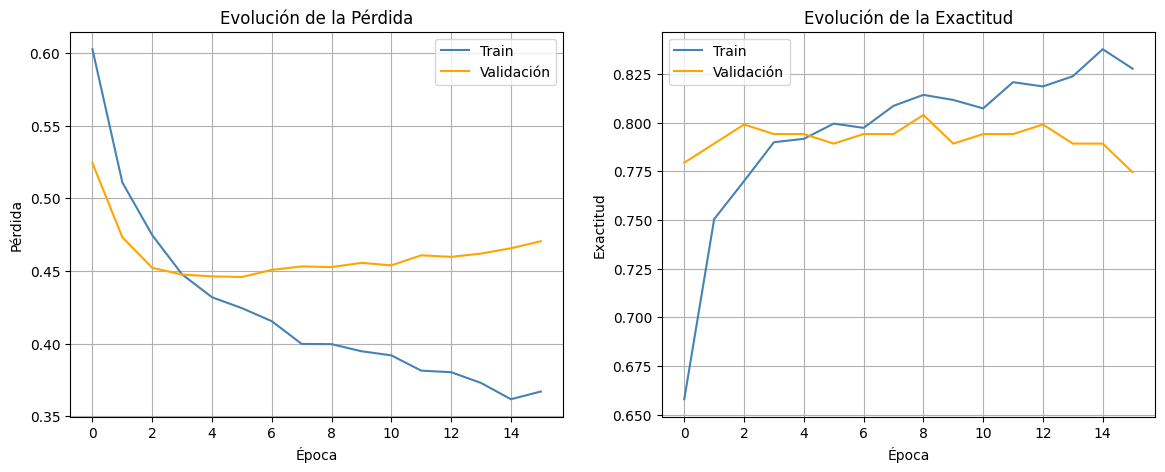

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss
ax1.plot(history.history['loss'], label='Train', color='steelblue')
ax1.plot(history.history['val_loss'], label='Validación', color='orange')
ax1.set_title('Evolución de la Pérdida')
ax1.set_xlabel('Época')
ax1.set_ylabel('Pérdida')
ax1.legend()
ax1.grid(True)

# Accuracy
ax2.plot(history.history['binary_accuracy'], label='Train', color='steelblue')
ax2.plot(history.history['val_binary_accuracy'], label='Validación', color='orange')
ax2.set_title('Evolución de la Exactitud')
ax2.set_xlabel('Época')
ax2.set_ylabel('Exactitud')
ax2.legend()
ax2.grid(True)

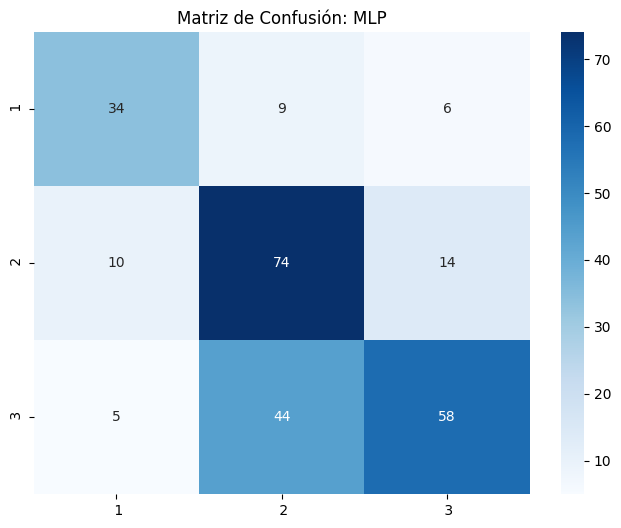

In [ ]:
cm_MLP = confusion_matrix(y_test_final_label, y_pred_ordinal)
plt.figure(figsize=(8,6))
sns.heatmap(cm_MLP, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f' {i+1}' for i in range(3)],
            yticklabels=[f' {i+1}' for i in range(3)])
plt.title('Matriz de Confusión: MLP')
plt.show()

## **Logistic Regression**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score

# ─────────────────────────────────────────────
# HIPERPARÁMETROS LR
# ─────────────────────────────────────────────
C             = 0.01        # Menor regularización, mejor resultado en experimentos
SOLVER        = 'lbfgs'    # Mejor resultado en experimentos
MAX_ITER      = 1000       # Suficiente para converger

# ─────────────────────────────────────────────
# MODELO
# ─────────────────────────────────────────────
lr_model = LogisticRegression(
    C=C,
    solver=SOLVER,
    max_iter=MAX_ITER,
    random_state=42,
    multi_class='multinomial'
)

lr_model.fit(X_train_final, y_train_final_label)

# ─────────────────────────────────────────────
# EVALUACIÓN
# ─────────────────────────────────────────────
y_pred_lr = lr_model.predict(X_test_final)

y_proba_lr = lr_model.predict_proba(X_test_final)
aucs_lr = calcular_auc_por_clase(y_test_final_label, y_proba_lr)
print("\nLR AUC por clase:")
for k, v in aucs_lr.items():
    print(f"  {k}: {v}")

print(classification_report(y_test_final_label, y_pred_lr))
f1_macro = f1_score(y_test_final_label, y_pred_lr, average='macro')
print(f"F1 Macro: {f1_macro:.3f}")


LR AUC por clase:
  AUC Clase 1: 0.872
  AUC Clase 2: 0.77
  AUC Clase 3: 0.841
  AUC Macro: 0.828
              precision    recall  f1-score   support

           1       0.55      0.73      0.63        49
           2       0.59      0.57      0.58        98
           3       0.72      0.63      0.67       107

    accuracy                           0.63       254
   macro avg       0.62      0.64      0.63       254
weighted avg       0.64      0.63      0.63       254

F1 Macro: 0.625


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [ ]:
# ─────────────────────────────────────────────
# TABLA RESUMEN ESTILO TUTOR
# ─────────────────────────────────────────────
from sklearn.metrics import accuracy_score

auc_macro = aucs_lr['AUC Macro']

tabla = []
for c in [1, 2, 3]:
    report = classification_report(y_test_final_label, y_pred_lr, output_dict=True, zero_division=0)
    tabla.append({
        'Clase': f'{c}',
        'Precision': round(report[str(c)]['precision'], 3),
        'Recall':    round(report[str(c)]['recall'], 3),
        'F1-score':  round(report[str(c)]['f1-score'], 3),
        'AUC':       aucs_lr[f'AUC Clase {c}']
    })

df_tabla = pd.DataFrame(tabla)
print("\n===== TABLA RESULTADOS POR CLASE =====")
print(df_tabla.to_string(index=False))

print("\n===== MÉTRICAS GLOBALES =====")
print(f"Accuracy:    {round(accuracy_score(y_test_final_label, y_pred_lr), 3)}")
print(f"F1 Macro:    {round(f1_score(y_test_final_label, y_pred_lr, average='macro'), 3)}")
print(f"F1 Weighted: {round(f1_score(y_test_final_label, y_pred_lr, average='weighted'), 3)}")
print(f"AUC Macro:   {auc_macro}")


===== TABLA RESULTADOS POR CLASE =====
Clase  Precision  Recall  F1-score   AUC
    1      0.545   0.735     0.626 0.872
    2      0.589   0.571     0.580 0.770
    3      0.720   0.626     0.670 0.841

===== MÉTRICAS GLOBALES =====
Accuracy:    0.626
F1 Macro:    0.625
F1 Weighted: 0.627
AUC Macro:   0.828


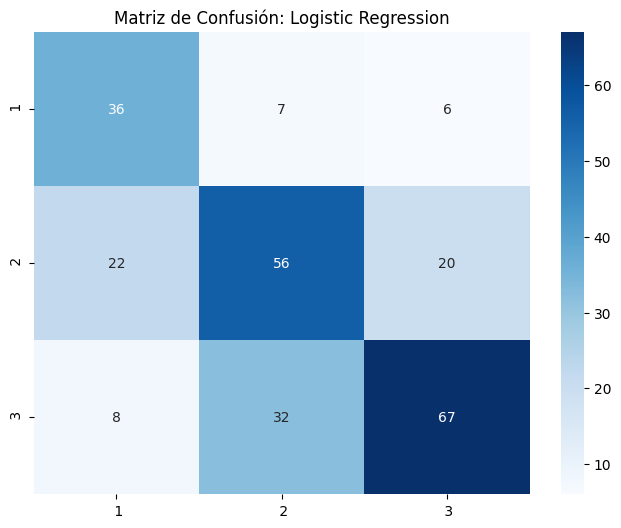

In [ ]:
cm_lr = confusion_matrix(y_test_final_label, y_pred_lr)
plt.figure(figsize=(8,6))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f' {i+1}' for i in range(3)],
            yticklabels=[f' {i+1}' for i in range(3)])
plt.title('Matriz de Confusión: Logistic Regression')
plt.show()

## **XGBoost**

In [ ]:
import xgboost as xgb
from sklearn.metrics import classification_report, f1_score, accuracy_score, roc_auc_score
from sklearn.preprocessing import label_binarize

# ─────────────────────────────────────────────
# HIPERPARÁMETROS XGBOOST
# ─────────────────────────────────────────────
N_ESTIMATORS  = 44   # Más árboles mejora el resultado
MAX_DEPTH     = 5    # Profundidad óptima en experimentos
LEARNING_RATE = 0.1  # LR bajo: mejor F1 Macro y clase 1
SUBSAMPLE     = 0.8   # Porcentaje de datos por árbol
GAMMA         = 0     # Sin regularización adicional (gamma=0.1 destruía clase 1)
COLSAMPLE     = 0.8   # Porcentaje de variables por árbol

# ─────────────────────────────────────────────
# MODELO
# ─────────────────────────────────────────────
xgb_model = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=3,
    n_estimators=N_ESTIMATORS,
    max_depth=MAX_DEPTH,
    learning_rate=LEARNING_RATE,
    subsample=SUBSAMPLE,
    gamma=GAMMA,
    colsample_bytree=COLSAMPLE,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
        X_train_final,
        y_train_final_label - 1,
        eval_set=[(X_train_final, y_train_final_label - 1),(X_val_final, y_val_final_label - 1)],
        verbose=False
    )

# ─────────────────────────────────────────────
# EVALUACIÓN
# ─────────────────────────────────────────────
y_pred_xgb = xgb_model.predict(X_test_final) + 1

y_proba_xgb = xgb_model.predict_proba(X_test_final)
aucs_xgb = calcular_auc_por_clase(y_test_final_label, y_proba_xgb)
print("XGBoost AUC por clase:")
for k, v in aucs_xgb.items():
    print(f"  {k}: {v}")

print(classification_report(y_test_final_label,y_pred_xgb))
f1_macro = f1_score(y_test_final_label, y_pred_xgb, average='macro')
print(f"F1 Macro: {f1_macro:.3f}")

XGBoost AUC por clase:
  AUC Clase 1: 0.882
  AUC Clase 2: 0.751
  AUC Clase 3: 0.834
  AUC Macro: 0.822
              precision    recall  f1-score   support

           1       0.60      0.69      0.64        49
           2       0.65      0.58      0.61        98
           3       0.72      0.73      0.72       107

    accuracy                           0.67       254
   macro avg       0.65      0.67      0.66       254
weighted avg       0.67      0.67      0.66       254

F1 Macro: 0.659


In [ ]:
# ─────────────────────────────────────────────
# TABLA RESUMEN ESTILO TUTOR
# ─────────────────────────────────────────────
from sklearn.metrics import accuracy_score

auc_macro = aucs_xgb['AUC Macro']

tabla = []
for c in [1, 2, 3]:
    report = classification_report(y_test_final_label, y_pred_xgb, output_dict=True, zero_division=0)
    tabla.append({
        'Clase': f'{c}',
        'Precision': round(report[str(c)]['precision'], 3),
        'Recall':    round(report[str(c)]['recall'], 3),
        'F1-score':  round(report[str(c)]['f1-score'], 3),
        'AUC':       aucs_xgb[f'AUC Clase {c}']
    })

df_tabla = pd.DataFrame(tabla)
print("\n===== TABLA RESULTADOS POR CLASE =====")
print(df_tabla.to_string(index=False))

print("\n===== MÉTRICAS GLOBALES =====")
print(f"Accuracy:    {round(accuracy_score(y_test_final_label, y_pred_xgb), 3)}")
print(f"F1 Macro:    {round(f1_score(y_test_final_label, y_pred_xgb, average='macro'), 3)}")
print(f"F1 Weighted: {round(f1_score(y_test_final_label, y_pred_xgb, average='weighted'), 3)}")
print(f"AUC Macro:   {auc_macro}")


===== TABLA RESULTADOS POR CLASE =====
Clase  Precision  Recall  F1-score   AUC
    1      0.596   0.694     0.642 0.882
    2      0.648   0.582     0.613 0.751
    3      0.716   0.729     0.722 0.834

===== MÉTRICAS GLOBALES =====
Accuracy:    0.665
F1 Macro:    0.659
F1 Weighted: 0.664
AUC Macro:   0.822


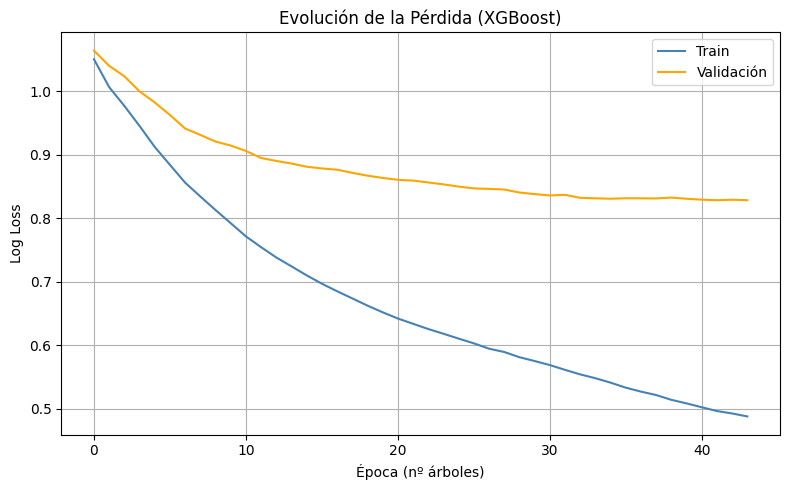

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(8, 5))

ax.plot(xgb_model.evals_result()['validation_0']['mlogloss'], label='Train', color='steelblue')
ax.plot(xgb_model.evals_result()['validation_1']['mlogloss'], label='Validación', color='orange')
ax.set_title('Evolución de la Pérdida (XGBoost)')
ax.set_xlabel('Época (nº árboles)')
ax.set_ylabel('Log Loss')
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()

<Figure size 800x600 with 0 Axes>

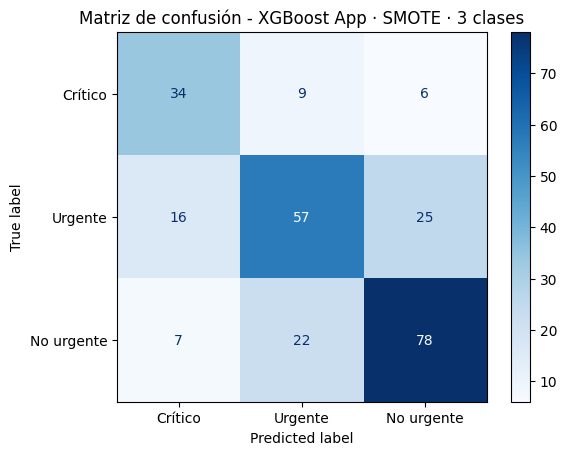

In [ ]:
cm_XGB = confusion_matrix(y_test_final_label, y_pred_xgb)
plt.figure(figsize=(8,6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_XGB,
                               display_labels=['Crítico', 'Urgente', 'No urgente'])
disp.plot(cmap='Purples')
plt.title('Matriz de confusión - XGBoost App · SMOTE · 3 clases')
plt.show()

**Analisis SHAP**

/tmp/ipykernel_5623/1960600360.py:7: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test_final,


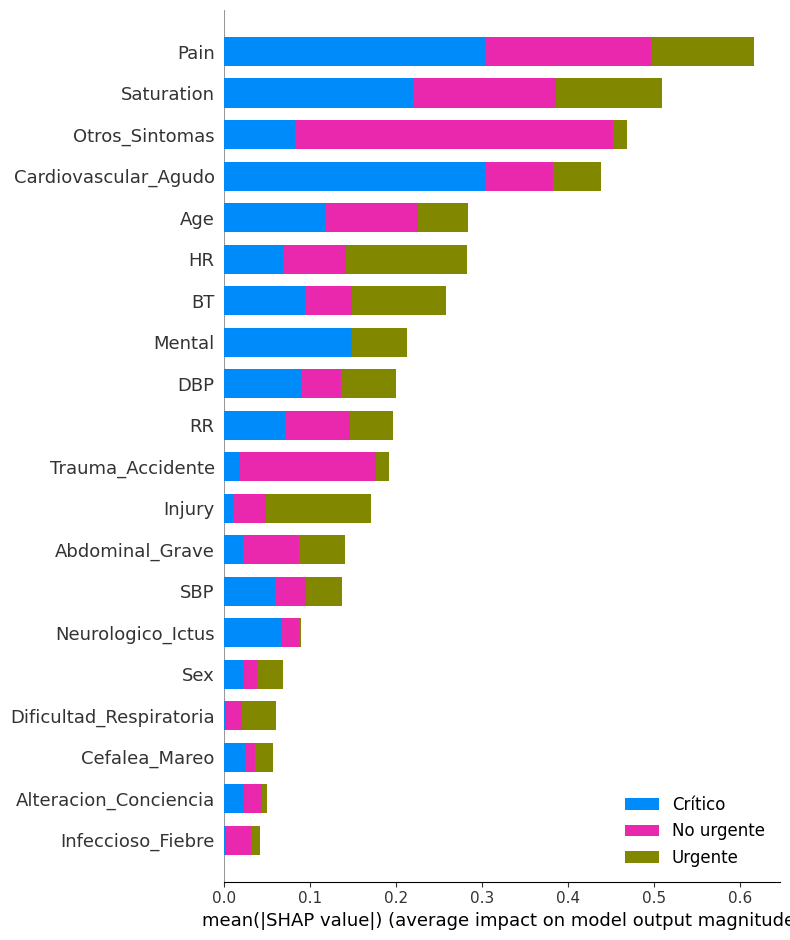

<Figure size 640x480 with 0 Axes>

/tmp/ipykernel_5623/1960600360.py:15: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test_final,
/usr/local/lib/python3.12/dist-packages/shap/plots/_beeswarm.py:723: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(
/usr/local/lib/python3.12/dist-packages/shap/plots/_beeswarm.py:743: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(
/usr/local/lib/python3.12/dist-packages/shap/plots/_beeswarm.py:743: 

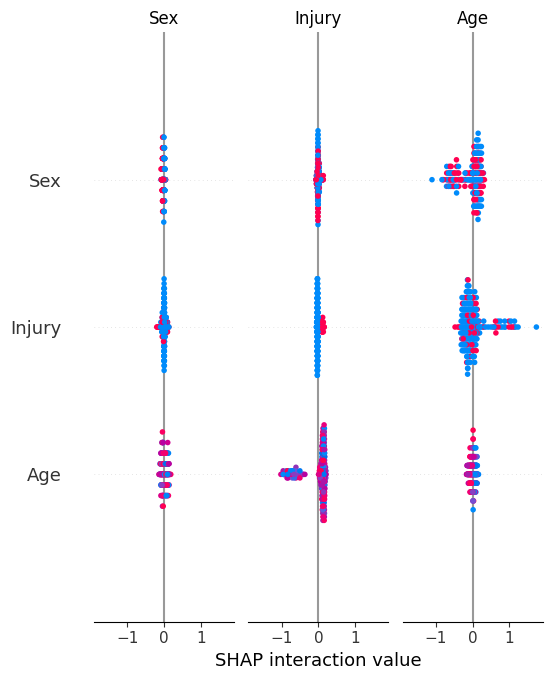

<Figure size 640x480 with 0 Axes>

In [ ]:
import shap

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_final)

# Importancia global de variables
shap.summary_plot(shap_values, X_test_final,
                  feature_names=feature_names,
                  plot_type='bar',
                  class_names=['Crítico', 'Urgente', 'No urgente'])
plt.savefig('shap_importance.png', dpi=150)
plt.show()

# Detalle por clase
shap.summary_plot(shap_values, X_test_final,
                  feature_names=feature_names,
                  class_names=['Crítico', 'Urgente', 'No urgente'])
plt.savefig('shap_detail.png', dpi=150)
plt.show()

/tmp/ipykernel_5623/1328241043.py:10: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


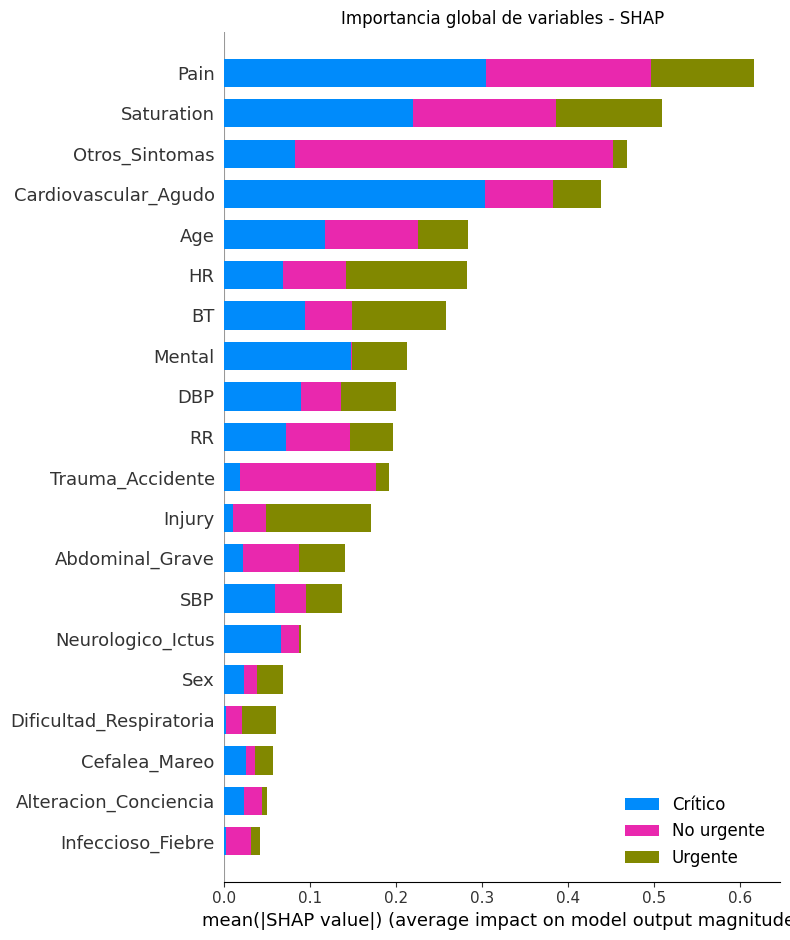

/tmp/ipykernel_5623/1328241043.py:25: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


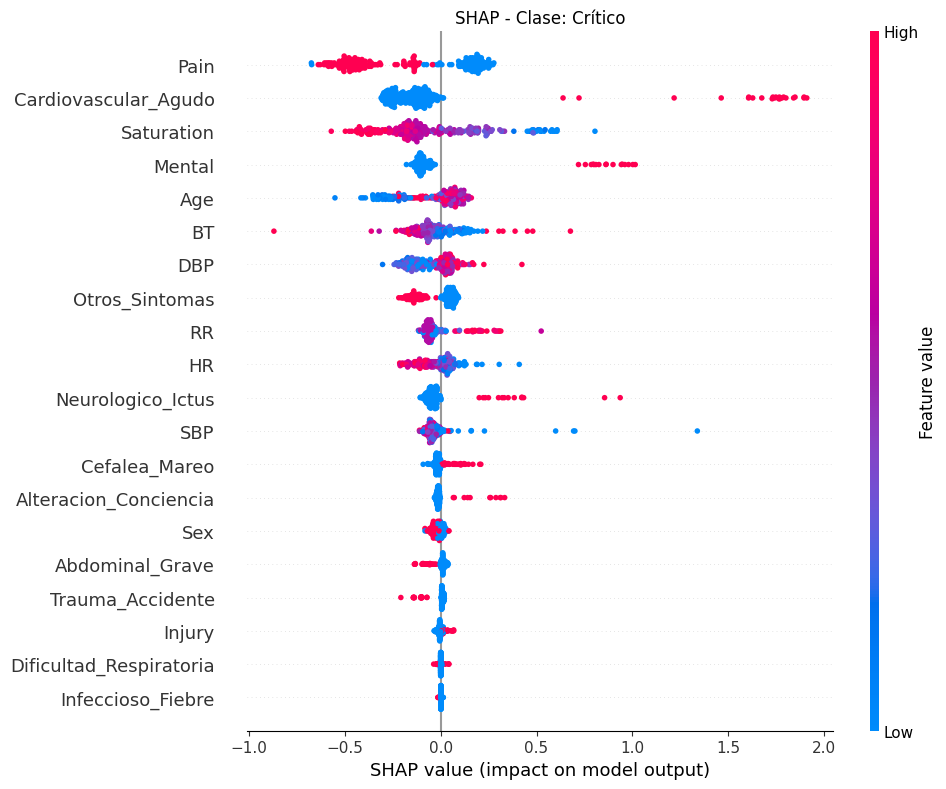

/tmp/ipykernel_5623/1328241043.py:25: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


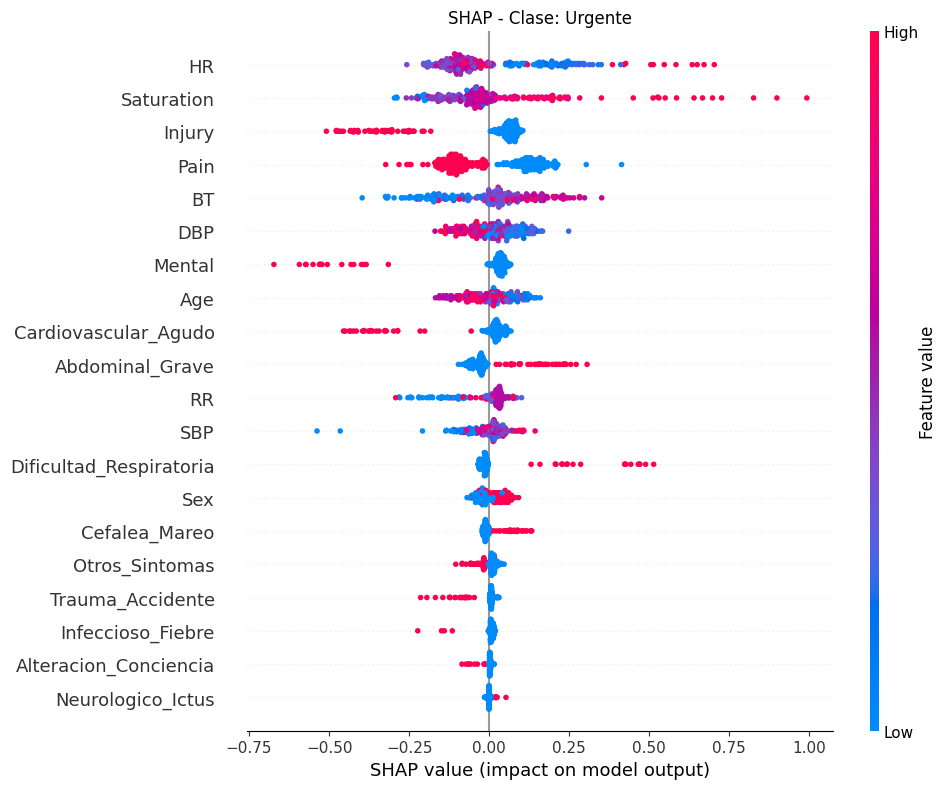

/tmp/ipykernel_5623/1328241043.py:25: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


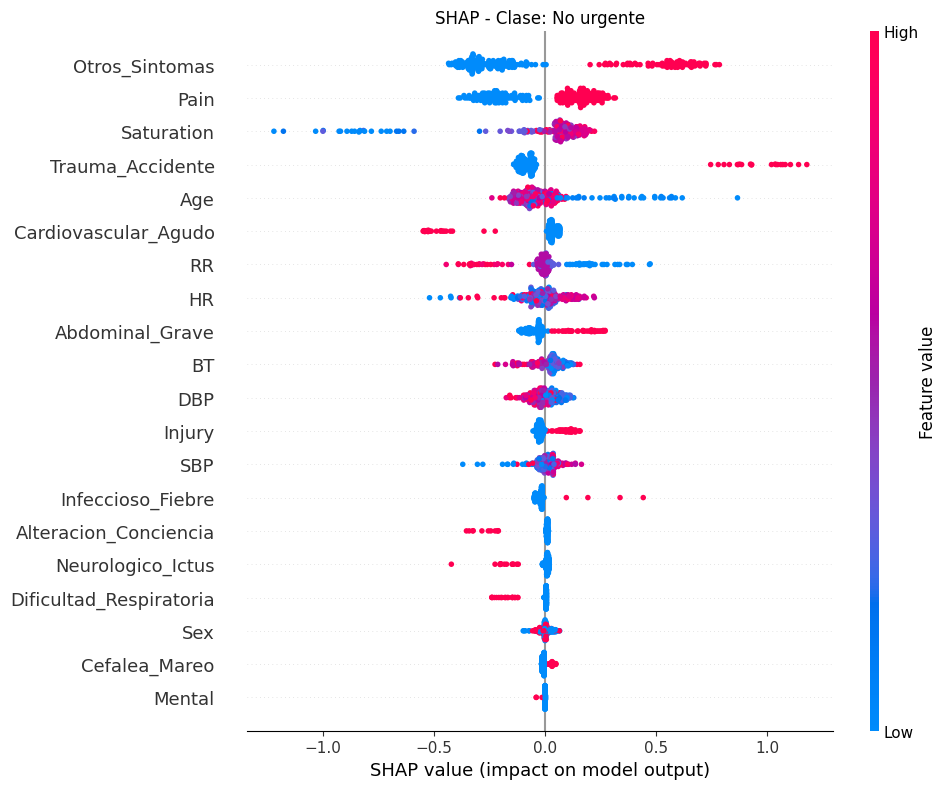

In [ ]:
import shap
import matplotlib.pyplot as plt

explainer = shap.TreeExplainer(xgb_model)
shap_explanation = explainer(X_test_final)

class_names = ['Crítico', 'Urgente', 'No urgente']

# Gráfica de importancia global
shap.summary_plot(
    shap_explanation.values,
    X_test_final,
    feature_names=feature_names,
    plot_type='bar',
    class_names=class_names,
    show=False
)
plt.title('Importancia global de variables - SHAP')
plt.tight_layout()
plt.savefig('shap_global.png', dpi=150)
plt.show()

# Gráfica por clase
for i, clase in enumerate(class_names):
    shap.summary_plot(
        shap_explanation.values[:, :, i],
        X_test_final,
        feature_names=feature_names,
        show=False,
        plot_size=(10, 8)
    )
    plt.title(f'SHAP - Clase: {clase}')
    plt.tight_layout()
    plt.savefig(f'shap_{clase}.png', dpi=150)
    plt.show()

# **ESEMBLE LEARNING**

In [ ]:
!pip install scikit-learn==1.5.2 scikeras

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 54.5 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
umap-learn 0.5.12 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
hdbscan 0.8.42 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.


In [ ]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from scikeras.wrappers import KerasClassifier
from sklearn.metrics import classification_report, mean_absolute_error

# 1. Definir la función del modelo (Asegúrate de que esta celda se ejecute)
def create_model_stacking():
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Dense, Dropout
    from tensorflow.keras.optimizers import Adam

    model = Sequential()
    # Usamos tus mejores parámetros: 32 y 96 unidades
    model.add(Dense(128, activation='relu', input_dim=X_train_final.shape[1]))
    model.add(Dropout(0.3))
    model.add(Dense(96, activation='relu'))
    model.add(Dropout(0.2))
    model.add(Dense(5, activation='softmax')) # 5 clases

    model.compile(optimizer=Adam(learning_rate=0.0006308),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# 2. Crear el componente de la Red Neuronal
nn_component = KerasClassifier(
    model=create_model_stacking,
    epochs=100,
    batch_size=32,
    verbose=0
)

# 3. COMPROBACIÓN CRÍTICA: Verifica que nada sea '0'
if not hasattr(grid_xgb, 'best_estimator_'):
    print("ERROR: El objeto grid_xgb no ha sido entrenado o no tiene best_estimator_")
else:
    # Definir la lista de modelos base
    base_models = [
        ('xgb', grid_xgb.best_estimator_),
        ('nn', nn_component)
    ]

    # 4. Configurar el Stacking
    stack_model = StackingClassifier(
        estimators=base_models,
        final_estimator=LogisticRegression(max_iter=1000),
        cv=5, # Validación cruzada interna como recomienda IBM
        stack_method='predict_proba'
    )

    # 5. Entrenamiento (Asegúrate de que y tenga valores 0,1,2,3,4)
    print("Entrenando Stacking... (esto puede tardar unos minutos por el CV=5)")
    stack_model.fit(X_train_final, y_train_res - 1)

    # 6. Evaluación
    y_pred_stack = stack_model.predict(X_test_final) + 1 # Volver a escala 1-5
    print("\n=== REPORTE FINAL STACKING 5 CLASES ===")
    print(classification_report(y_test_res, y_pred_stack))
    print(f"MAE Final: {mean_absolute_error(y_test_res, y_pred_stack):.4f}")


Entrenando Stacking... (esto puede tardar unos minutos por el CV=5)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr


=== REPORTE FINAL STACKING 5 CLASES ===
              precision    recall  f1-score   support

           1       0.95      0.54      0.69        98
           2       0.50      0.66      0.57        98
           3       0.52      0.64      0.57        98
           4       0.53      0.72      0.61        98
           5       0.78      0.40      0.53        98

    accuracy                           0.59       490
   macro avg       0.66      0.59      0.60       490
weighted avg       0.66      0.59      0.60       490

MAE Final: 0.5469


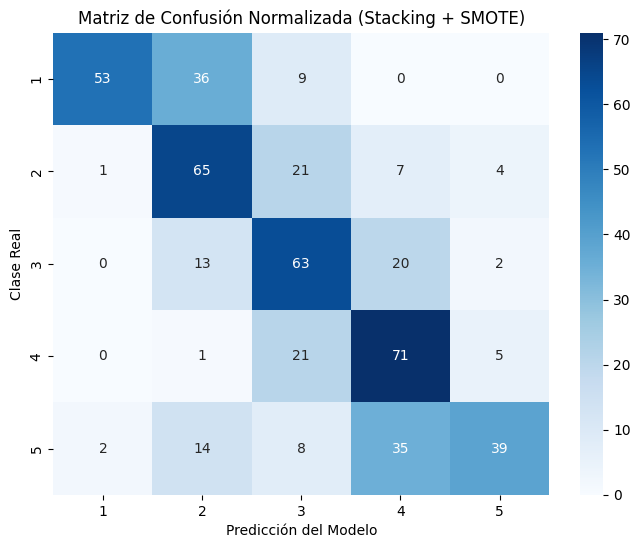

In [ ]:
# 1. Generar la matriz
cm = confusion_matrix(y_test_res, y_pred_stack)
# 3. Graficar
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, cmap='Blues',
            xticklabels=[1,2,3,4,5], yticklabels=[1,2,3,4,5])

plt.title('Matriz de Confusión Normalizada (Stacking + SMOTE)')
plt.ylabel('Clase Real')
plt.xlabel('Predicción del Modelo')
plt.show()